# 04 - Anomaly detection and defect localization (Phase 3)

Reconstruction-based anomaly detection on the **bottle** category of MVTec AD,
using the trained Phase-2 baseline from `notebooks/03_baseline_autoencoder.ipynb`.

**Roadmap (one step per section, confirmed before the next step is implemented):**

| Step | Content |
|---|---|
| 1 | Validate the trained checkpoint |
| 2 | Anomaly scoring - `src/anomaly/scoring.py` |
| 3 | Heatmaps and thresholded masks - `src/anomaly/heatmap.py` |
| 4 | Official test-set inference (labels kept out of inference) |
| 5 | Threshold selection without test leakage |
| 6 | Metrics - `src/evaluation/metrics.py` |
| 7 | Visualize detections and failure cases |
| 8 | Reproducible result saving |

**Research rules for this phase**

- The baseline is **never** retrained on defective images and never sees ground-truth masks.
- Ground-truth masks are loaded for evaluation only, never for scoring or threshold tuning.
- No multi-scale or edge-aware scoring yet - those belong to later phases.
- Every cell fails loudly when a prerequisite is missing: this notebook never
  silently builds a randomly initialized model and presents it as the trained baseline.
- Run the notebook top to bottom on a Colab runtime (GPU recommended, not required
  for inference). Local runs work too - only the paths differ.

## Step 1 - Validate the trained model

This project does *reconstruction-based* anomaly detection: the autoencoder was
trained only on normal images, so it reconstructs normal structure well and
reconstructs previously unseen defects poorly. Every later number (heatmap,
AUROC, Dice) is only as trustworthy as the checkpoint it comes from, so Phase 3
starts by strictly validating the Phase-2 artifacts.

What "the trained model" is on disk (written by `Trainer` in
`src/training/trainer.py:245`):

```text
outputs/runs/baseline_bottle/
├── checkpoints/best.pt    # weights of the lowest-validation-MSE epoch (~61.5 MB)
├── checkpoints/last.pt    # final epoch (used to resume training)
├── config.yaml            # the exact hyperparameters of that run
├── history.json           # per-epoch train/validation losses
├── metadata.json          # GPU, torch version, parameter count, losses
└── split_info.json        # which normal images were used for train/validation
```

`best.pt` is a dictionary, not a bare state dict: `epoch`, `model_state_dict`,
`optimizer_state_dict`, `records`, `best_metric`, `config`, `rng` and
`torch_version`. Validation performed in Step 1:

1. **Locate** the run directory by probing explicit candidates. If no checkpoint
   is found, stop with recovery instructions - never guess and never substitute.
2. **Reconstruct the architecture** from the config stored *inside* the
   checkpoint (the source of truth), cross-checked against the run's `config.yaml`.
3. **Load the weights** with `strict=True` on the chosen device, then call
   `model.eval()` - from now on BatchNorm uses its running statistics, which is
   what inference and scoring must use.
4. **Smoke test**: reconstruct normal test images and check shape equality,
   finiteness and value range, then display the result.

**If the checkpoint is missing** (Colab runtimes are ephemeral and `/content` is
wiped when a session dies; large artifacts are gitignored on purpose), this
notebook raises `FileNotFoundError` with three recovery options: use the still-alive
runtime, restore `outputs/runs/baseline_bottle/` from Google Drive (set
`BASELINE_RUN_DIR` to that folder), or re-run notebook 03 (~3 minutes on a T4,
uses `train/good` only).

In [13]:
# Locate the repository root on this runtime (same probe pattern as notebooks 01/03).
from pathlib import Path

REPO_DIR_NAME = "edge-aware-anomaly-detection"

# Priority order:
#   1. cwd / its parent   - local kernel, or a kernel started inside notebooks/
#   2. /content/<repo>    - whole repo uploaded via right-click -> Upload to Colab
#   3. Google Drive copy  - only if Drive was mounted and holds a repo copy
#   4. /content           - fallback when only src/ was uploaded
CANDIDATE_ROOTS = [
    Path.cwd(),
    Path.cwd().parent,
    Path("/content") / REPO_DIR_NAME,
    Path("/content/drive/MyDrive") / REPO_DIR_NAME,
    Path("/content"),
]


def _is_repo_root(path: Path) -> bool:
    return (path / "src" / "config.py").is_file() and (path / "notebooks").is_dir()


print("Probe results:")
hits = []
for root in CANDIDATE_ROOTS:
    hit = _is_repo_root(root)
    print(f"  {'HIT ' if hit else 'miss'}  {root}")
    if hit:
        hits.append(root)

if not hits:
    raise FileNotFoundError(
        "Repository root not found on this runtime.\n"
        "Fix: in the VS Code Explorer, right-click the repository folder "
        f"('{REPO_DIR_NAME}') -> 'Upload to Colab', then re-run this cell."
    )

REPO_ROOT = hits[0]
if len(hits) > 1:
    print(f"\nMultiple hits; using the first: {REPO_ROOT}")

missing = [
    name
    for name in ("src", "configs", "notebooks", "requirements.txt", ".gitignore")
    if not (REPO_ROOT / name).exists()
]
if missing:
    raise FileNotFoundError(
        f"Found the repo under {REPO_ROOT}, but {missing} is missing there.\n"
        "Only part of the repository was uploaded. Upload the WHOLE folder "
        f"('{REPO_DIR_NAME}'): right-click it -> 'Upload to Colab'."
    )

print(f"\nCurrent working directory: {Path.cwd()}")
print(f"Repository root:            {REPO_ROOT}")

Probe results:
  miss  /content
  miss  /
  HIT   /content/edge-aware-anomaly-detection
  miss  /content/drive/MyDrive/edge-aware-anomaly-detection
  miss  /content

Current working directory: /content
Repository root:            /content/edge-aware-anomaly-detection


In [14]:
# Import the reused Phase-2 modules and print checksums (staleness guard).
import datetime
import json
import sys
from pathlib import Path

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import src
from src import config as project_config
from src.config import (
    ExperimentConfig,
    file_sha256,
    get_device,
    get_paths,
    load_experiment_config,
    set_seed,
)
from src.data import NormalImageDataset, build_transform, find_dataset_root, scan_category
from src.losses import absolute_error_map, per_image_mse
from src.models import Autoencoder, count_parameters_by_part, count_trainable_parameters

SRC_MODULES = [
    project_config.__file__,
    Path(src.__file__).parent / "data" / "dataset.py",
    Path(src.__file__).parent / "models" / "encoder.py",
    Path(src.__file__).parent / "models" / "decoder.py",
    Path(src.__file__).parent / "models" / "autoencoder.py",
    Path(src.__file__).parent / "losses" / "reconstruction.py",
    Path(src.__file__).parent / "anomaly" / "scoring.py",
    Path(src.__file__).parent / "anomaly" / "heatmap.py",
    Path(src.__file__).parent / "evaluation" / "metrics.py",
]

src_file = Path(src.__file__).resolve()
repo_resolved = REPO_ROOT.resolve()
assert src_file.is_relative_to(repo_resolved), (
    f"Imported 'src' from {src_file}, which is not under {repo_resolved}. "
    "A different 'src' package is shadowing the project module - restart the "
    "kernel and re-run from the top."
)

print(f"src package     : {src_file}")
print(f"src.__version__ : {src.__version__}")
print()

missing_src = [Path(module_path) for module_path in SRC_MODULES if not Path(module_path).is_file()]
if missing_src:
    listed = "\n".join(f"  - {p}" for p in missing_src)
    raise FileNotFoundError(
        "Source file(s) missing on this runtime:\n"
        f"{listed}\n"
        "This is a STALE UPLOAD: the repository copy on the runtime is older than "
        "your local one (Phase 3 added src/anomaly/). Fix: in VS Code, right-click "
        "the repository folder -> 'Upload to Colab', then re-run this cell. "
        "Expected local hash for src/anomaly/scoring.py: sha256 9c7f1f9ad211."
    )

for module_path in SRC_MODULES:
    path = Path(module_path)
    mtime = datetime.datetime.fromtimestamp(path.stat().st_mtime)
    print(
        f"{path.relative_to(repo_resolved)}  sha256 {project_config.file_sha256(path)}  "
        f"mtime {mtime:%Y-%m-%d %H:%M}"
    )

print("\nStaleness guard: re-upload the repository folder after editing src/ locally.")
SRC_OK = True

src package     : /content/edge-aware-anomaly-detection/src/__init__.py
src.__version__ : 0.1.0

src/config.py  sha256 487ccae672ef  mtime 2026-10-15 17:23
src/data/dataset.py  sha256 ebf144dbbc9c  mtime 2026-10-15 17:23
src/models/encoder.py  sha256 6b44d5165fe8  mtime 2026-10-15 17:23
src/models/decoder.py  sha256 dbb5dfc56f0c  mtime 2026-10-15 17:23
src/models/autoencoder.py  sha256 184b52f14680  mtime 2026-10-15 17:23
src/losses/reconstruction.py  sha256 860d59ff382a  mtime 2026-10-15 17:23
src/anomaly/scoring.py  sha256 9c7f1f9ad211  mtime 2026-10-15 17:22
src/anomaly/heatmap.py  sha256 ef04535e8916  mtime 2026-10-15 17:22
src/evaluation/metrics.py  sha256 c8880ccb3142  mtime 2026-10-15 17:23

Staleness guard: re-upload the repository folder after editing src/ locally.


In [15]:
# Reproducibility seed + device selection (GPU preferred; CPU is valid for inference).
SEED = project_config.SEED
set_seed(SEED)
paths = get_paths()
DEVICE = get_device()

print(f"seed            : {SEED} (python/numpy/torch/CUDA, deterministic cuDNN)")
print(f"device          : {DEVICE}")
if DEVICE.type == "cpu":
    print("note: CUDA not available - inference will run on CPU (slower, same results).")
print(f"outputs root    : {paths.outputs}")
print(f"configs         : {paths.configs}")

seed            : 42 (python/numpy/torch/CUDA, deterministic cuDNN)
device          : cuda
outputs root    : /content/edge-aware-anomaly-detection/outputs
configs         : /content/edge-aware-anomaly-detection/configs


In [16]:
# Locate the Phase-2 run directory. Explicit candidates only; fail loudly if absent.
import os

base_cfg = load_experiment_config(paths.configs / "default.yaml")
EXPERIMENT_NAME = base_cfg.experiment_name
CATEGORY = base_cfg.category

env_run = os.environ.get("BASELINE_RUN_DIR")
CANDIDATE_RUN_DIRS = [
    Path(p)
    for p in (
        env_run,  # explicit override (e.g. a restored run on Google Drive)
        paths.outputs / "runs" / EXPERIMENT_NAME,
        Path("/content/drive/MyDrive") / REPO_DIR_NAME / "outputs" / "runs" / EXPERIMENT_NAME,
        Path.cwd() / "outputs" / "runs" / EXPERIMENT_NAME,
    )
    if p
]

print(f"experiment      : {EXPERIMENT_NAME}")
print(f"category        : {CATEGORY}")
print("Run-directory candidates:")
run_dirs = []
for candidate in CANDIDATE_RUN_DIRS:
    exists = candidate.is_dir()
    print(f"  {'HIT ' if exists else 'miss'}  {candidate}")
    if exists and candidate not in run_dirs:
        run_dirs.append(candidate)

best_candidates = [d / "checkpoints" / "best.pt" for d in run_dirs if (d / "checkpoints" / "best.pt").is_file()]

if not best_candidates:
    raise FileNotFoundError(
        "Trained baseline checkpoint (checkpoints/best.pt) not found. Phase 3 "
        "cannot start: anomaly detection must load the Phase-2 weights, and this "
        "notebook will NOT build a randomly initialized substitute.\n"
        "Recover the run (pick ONE):\n"
        "  1. Colab runtime still alive: the run lives in <repo>/outputs/runs/"
        f"{EXPERIMENT_NAME}/ on the runtime - re-upload the repo if the kernel changed.\n"
        "  2. Restore that run folder from Google Drive and set the environment\n"
        "     variable BASELINE_RUN_DIR to it (os.environ['BASELINE_RUN_DIR'] = ...).\n"
        f"  3. Re-run notebooks/03_baseline_autoencoder.ipynb end to end (train/good only,\n"
        "     ~3 min on a T4) to retrain and re-save best.pt.\n"
        "Note: outputs/ and *.pt are gitignored on purpose, so git history has no copy."
    )

RUN_DIR = best_candidates[0].parent.parent
BEST_CKPT = RUN_DIR / "checkpoints" / "best.pt"
if len(best_candidates) > 1:
    print(f"multiple runs found; using the first: {RUN_DIR}")

EXPECTED_ARTIFACTS = [
    "checkpoints/best.pt",
    "checkpoints/last.pt",
    "config.yaml",
    "history.json",
    "metadata.json",
    "split_info.json",
]
print(f"\nRun directory: {RUN_DIR}")
missing_artifacts = []
for rel in EXPECTED_ARTIFACTS:
    artifact = RUN_DIR / rel
    if artifact.is_file():
        print(f"  ok    {rel:<26} {artifact.stat().st_size / 1024:>10.1f} KB")
    else:
        print(f"  MISS  {rel}")
        missing_artifacts.append(rel)

assert not missing_artifacts, (
    f"Run directory {RUN_DIR} is incomplete: missing {missing_artifacts}. "
    "Re-run notebook 03 (or restore the full run folder from Drive) - partial "
    "runs are not a valid starting point for evaluation."
)

CHECKPOINT_ID = file_sha256(BEST_CKPT, length=12)
print(f"\ncheckpoint id (sha256[:12]) : {CHECKPOINT_ID}")
print(f"checkpoint size             : {BEST_CKPT.stat().st_size / (1024 * 1024):.1f} MB")

history = json.loads((RUN_DIR / "history.json").read_text(encoding="utf-8"))
metadata = json.loads((RUN_DIR / "metadata.json").read_text(encoding="utf-8"))
assert history, f"{RUN_DIR / 'history.json'} contains no epochs"

first_epoch, last_epoch = history[0], history[-1]
print(f"history      : {len(history)} epochs, "
      f"train {first_epoch['train_loss']:.6f} -> {last_epoch['train_loss']:.6f}, "
      f"val {first_epoch['val_loss']:.6f} -> {last_epoch['val_loss']:.6f}")
params_meta = metadata.get("trainable_parameters")
print(f"trained on   : {metadata.get('gpu_name')} / torch {metadata.get('torch_version')}")
print(f"params (meta): {params_meta:,}" if isinstance(params_meta, int) else "params (meta): (not recorded)")
print(f"best metric  : {metadata.get('best_metric')}")

RUN_ARTIFACTS_OK = True

experiment      : baseline_bottle
category        : bottle
Run-directory candidates:
  HIT   /content/edge-aware-anomaly-detection/outputs/runs/baseline_bottle
  miss  /content/drive/MyDrive/edge-aware-anomaly-detection/outputs/runs/baseline_bottle
  miss  /content/outputs/runs/baseline_bottle

Run directory: /content/edge-aware-anomaly-detection/outputs/runs/baseline_bottle
  ok    checkpoints/best.pt           62968.1 KB
  ok    checkpoints/last.pt           62968.5 KB
  ok    config.yaml                       0.4 KB
  ok    history.json                      4.5 KB
  ok    metadata.json                     2.6 KB
  ok    split_info.json                  18.2 KB

checkpoint id (sha256[:12]) : aa21e2056301
checkpoint size             : 61.5 MB
history      : 30 epochs, train 0.068142 -> 0.001953, val 0.256651 -> 0.002036
trained on   : Tesla T4 / torch 2.11.0+cu130
params (meta): 5,363,395
best metric  : 0.0019207965981747424


### Loading strategy (why each option matters)

- `map_location="cpu"` first: the checkpoint was written on a Colab GPU; mapping
  to CPU lets the same file load on any machine, and the model is moved to
  `DEVICE` afterwards. Nothing silently fails because CUDA is missing.
- `weights_only=False` is required: the payload embeds Python/torch RNG states
  (tuples), which the restricted unpickler of recent `torch.load` versions
  refuses. These are our own files produced by our own `Trainer` - never load
  untrusted checkpoints with this flag.
- `strict=True` (the default of `load_state_dict`) aborts on any missing or
  unexpected key: if the architecture and the weights disagree, we stop instead
  of quietly keeping random layers.
- **Config precedence:** the config stored *inside* the checkpoint describes what
  was actually trained, so it wins over the run's `config.yaml`; the YAML is used
  only when the payload has none. `configs/default.yaml` is a last-resort
  fallback and is flagged loudly. Any mismatch between payload and YAML is printed.
- `model.eval()` switches BatchNorm from batch statistics to the running
  statistics learned during training - required for deterministic inference.

In [17]:
# Load the checkpoint payload, resolve the exact config, rebuild the architecture, load strictly.
import torch

payload = torch.load(BEST_CKPT, map_location="cpu", weights_only=False)
assert isinstance(payload, dict), (
    f"{BEST_CKPT} is a {type(payload).__name__}, not the dictionary written by "
    "Trainer.save_checkpoint - wrong file."
)
REQUIRED_PAYLOAD_KEYS = {"epoch", "model_state_dict", "records", "config", "torch_version"}
missing_keys = sorted(REQUIRED_PAYLOAD_KEYS - set(payload))
assert not missing_keys, (
    f"Checkpoint payload is missing {missing_keys}; found {sorted(payload)}. "
    "This file was not written by src.training.Trainer.save_checkpoint."
)
PAYLOAD_OK = True

print(f"payload keys      : {sorted(payload)}")
print(f"epoch             : {payload['epoch']}")
print(f"records           : {len(payload.get('records') or [])}")
print(f"best_metric       : {payload.get('best_metric')}")
print(f"saved with torch  : {payload.get('torch_version')}  (runtime: {torch.__version__})")

# --- config resolution: payload > run config.yaml > configs/default.yaml (flagged) ---
run_cfg_path = RUN_DIR / "config.yaml"
CONFIG_OK = True
if isinstance(payload.get("config"), dict):
    cfg = load_experiment_config(overrides=payload["config"])
    cfg_source = "checkpoint payload (config used during training)"
    if run_cfg_path.is_file():
        file_cfg = load_experiment_config(run_cfg_path)
        if file_cfg.to_dict() != cfg.to_dict():
            print(
                "WARNING: config.yaml differs from the payload config; using the "
                "payload config because it describes the actual training run."
            )
elif run_cfg_path.is_file():
    cfg = load_experiment_config(run_cfg_path)
    cfg_source = f"run file {run_cfg_path}"
else:
    cfg = load_experiment_config(paths.configs / "default.yaml")
    cfg_source = "configs/default.yaml (FALLBACK - payload and run config missing)"
    CONFIG_OK = False

print(f"config source     : {cfg_source}")
print(
    f"architecture      : in_ch={cfg.model.in_channels} base={cfg.model.base_channels} "
    f"mults={list(cfg.model.channel_mults)} latent={cfg.model.latent_channels} "
    f"convs/stage={cfg.model.num_convs_per_stage}"
)
print(f"image size        : {cfg.data.image_size}  (divisible by 2**{cfg.model.num_downsamples} = {cfg.model.downsample_factor})")
assert CONFIG_OK, "No run config found anywhere - restore config.yaml before continuing."

# --- rebuild the exact architecture, then load the trained weights ---
model = Autoencoder.from_config(cfg.model)
load_result = model.load_state_dict(payload["model_state_dict"], strict=True)
assert not list(load_result.missing_keys) and not list(load_result.unexpected_keys)
model = model.to(DEVICE)
model.eval()

n_params = count_trainable_parameters(model)
parts = count_parameters_by_part(model)
print(f"state dict        : strict load OK (missing={list(load_result.missing_keys)}, unexpected={list(load_result.unexpected_keys)})")
print(f"parameters        : {n_params:,}  (encoder {parts['encoder']:,} / decoder {parts['decoder']:,})")
if isinstance(params_meta, int):
    assert n_params == params_meta, (
        f"Parameter count {n_params:,} != metadata.json value {params_meta:,} - "
        "the architecture does not match the trained run."
    )
print(f"model training flag: {model.training}  (False = eval mode, ready for inference)")
WEIGHTS_OK = True
MODEL_EVAL_OK = model.training is False
assert MODEL_EVAL_OK, "model.eval() did not take effect"

payload keys      : ['best_metric', 'config', 'epoch', 'model_state_dict', 'optimizer_state_dict', 'records', 'rng', 'torch_version']
epoch             : 25
records           : 25
best_metric       : 0.0019207965981747424
saved with torch  : 2.11.0+cu130  (runtime: 2.11.0+cu130)
config source     : checkpoint payload (config used during training)
architecture      : in_ch=3 base=32 mults=[1, 2, 4, 8, 8] latent=256 convs/stage=2
image size        : 256  (divisible by 2**5 = 32)
state dict        : strict load OK (missing=[], unexpected=[])
parameters        : 5,363,395  (encoder 2,419,680 / decoder 2,943,715)
model training flag: False  (False = eval mode, ready for inference)


### Smoke test: reconstruct a normal test image

`test/good` holds only defect-free images, so a correctly trained baseline must
reconstruct them with a *low* error - notebook 03 measured per-image MSE around
`1e-3` with a worst-case channel-wise difference near `0.5`. A value an order of
magnitude larger here means wrong weights or wrong preprocessing.

Checks performed: input and output shapes are identical, every value is finite,
the reconstruction stays inside `[0, 1]` (sigmoid head), and
`absolute_error_map` - the primitive Step 2 will formalise as anomaly scoring -
returns non-negative values. The category scan also confirms that every
defective test image has a matching ground-truth mask on disk (structure check
only; the masks are never opened or passed to the model here).

In [18]:
# Reconstruct normal test images and verify the contract: shape, finiteness, range.
try:
    DATASET_ROOT = find_dataset_root()
except FileNotFoundError as exc:
    raise FileNotFoundError(
        f"{exc}\n"
        "This notebook needs the extracted MVTec AD dataset. Fix: run "
        "notebooks/02_dataset_inspection.ipynb (download + extract cells) first, "
        "or set MVTEC_ROOT to the folder that contains 'bottle', 'cable', ..."
    ) from None
print(f"dataset root      : {DATASET_ROOT}")
DATASET_OK = True

report = scan_category(DATASET_ROOT, CATEGORY, verify_images=False)
assert report.ok, "Category scan failed:\n" + "\n".join(report.errors)
print(
    f"bottle            : train/good {len(report.train_good)} | test/good {len(report.test_good)} | "
    f"test defective {report.n_test_defective} | masks {sum(len(v) for v in report.masks_by_defect.values())}"
)
SCAN_OK = True

SMOKE_PATHS = report.test_good[:4]
assert SMOKE_PATHS, "No normal test images found under test/good"
transform = build_transform(cfg.data.image_size)
smoke_dataset = NormalImageDataset(SMOKE_PATHS, transform)
smoke_batch = torch.stack([smoke_dataset[i]["image"] for i in range(len(smoke_dataset))]).to(DEVICE)

with torch.no_grad():
    smoke_recon = model(smoke_batch)

assert smoke_recon.shape == smoke_batch.shape, (
    f"Shape mismatch: input {tuple(smoke_batch.shape)} vs reconstruction "
    f"{tuple(smoke_recon.shape)}"
)
finite_ok = bool(torch.isfinite(smoke_recon).all()) and bool(torch.isfinite(smoke_batch).all())
range_ok = 0.0 <= float(smoke_recon.min()) and float(smoke_recon.max()) <= 1.0
err_map = absolute_error_map(smoke_recon, smoke_batch)          # (B, H, W), channel-averaged |x_hat - x|
img_mse = per_image_mse(smoke_recon, smoke_batch)               # (B,)
nonneg_ok = bool((err_map >= 0).all()) and bool(torch.isfinite(err_map).all())

print(f"input             : {tuple(smoke_batch.shape)} range [{float(smoke_batch.min()):.3f}, {float(smoke_batch.max()):.3f}]")
print(f"reconstruction    : {tuple(smoke_recon.shape)} range [{float(smoke_recon.min()):.3f}, {float(smoke_recon.max()):.3f}]  finite={finite_ok} in[0,1]={range_ok}")
print(f"error map         : mean {float(err_map.mean()):.6f}  max {float(err_map.max()):.6f}  finite+non-negative={nonneg_ok}")
print("per-image MSE     :")
for path, value in zip(SMOKE_PATHS, img_mse.tolist()):
    print(f"  {path.name:<14} {value:.6f}")

assert finite_ok and range_ok and nonneg_ok, "Reconstruction contract violated (see flags above)"
SMOKE_OK = True

dataset root      : /content/datasets/mvtec/kaggle/mvtec_anomaly_detection
bottle            : train/good 209 | test/good 20 | test defective 63 | masks 63
input             : (4, 3, 256, 256) range [0.114, 1.000]
reconstruction    : (4, 3, 256, 256) range [0.131, 0.999]  finite=True in[0,1]=True
error map         : mean 0.027445  max 0.637005  finite+non-negative=True
per-image MSE     :
  000.png        0.002044
  001.png        0.001931
  002.png        0.002564
  003.png        0.002214


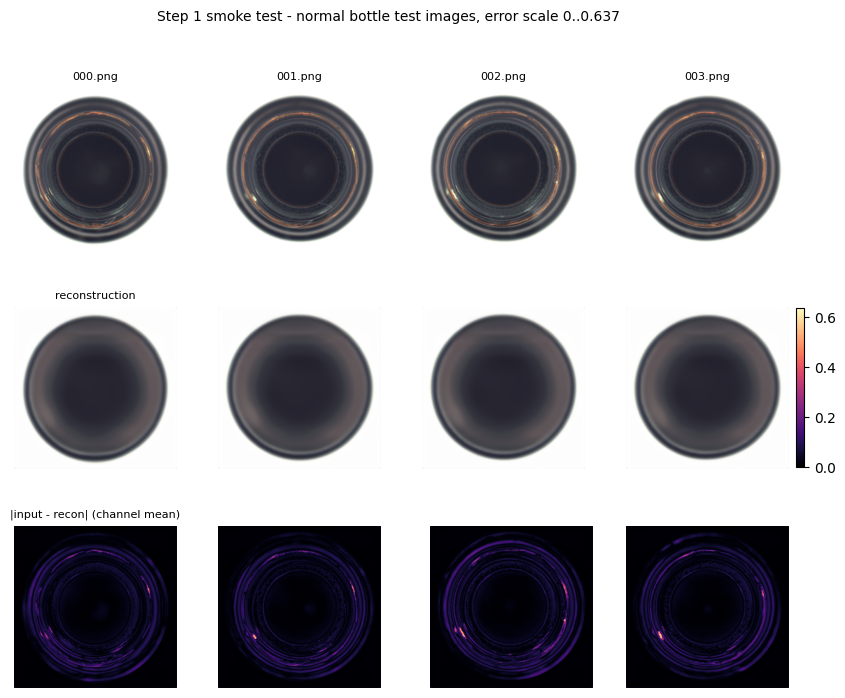

saved: /content/edge-aware-anomaly-detection/outputs/runs/baseline_bottle/figures/step1_smoke_reconstruction.png
Reading the panels: a good baseline shows a dull, low-valued error map on
normal images - defects will stand out much brighter in Steps 3-7.


In [19]:
# Visual check: original | reconstruction | absolute error (the Step-7 grid comes later).
import matplotlib.pyplot as plt

n_show = len(SMOKE_PATHS)
smoke_images = smoke_batch.cpu()
smoke_err_map = err_map.cpu()
shared_vmax = max(0.05, float(smoke_err_map.max()))

fig = plt.figure(figsize=(2.6 * n_show, 7.8))
gs = fig.add_gridspec(3, n_show, hspace=0.35, wspace=0.05)
for index in range(n_show):
    ax_in = fig.add_subplot(gs[0, index])
    ax_in.imshow(smoke_images[index].permute(1, 2, 0).clamp(0, 1))
    ax_in.set_title(Path(SMOKE_PATHS[index]).name, fontsize=8)
    ax_in.axis("off")

    ax_re = fig.add_subplot(gs[1, index])
    ax_re.imshow(smoke_recon[index].cpu().permute(1, 2, 0).clamp(0, 1))
    if index == 0:
        ax_re.set_title("reconstruction", fontsize=8)
    ax_re.axis("off")

    ax_er = fig.add_subplot(gs[2, index])
    im = ax_er.imshow(smoke_err_map[index], cmap="magma", vmin=0.0, vmax=shared_vmax)
    if index == 0:
        ax_er.set_title("|input - recon| (channel mean)", fontsize=8)
    ax_er.axis("off")

fig.colorbar(im, ax=fig.axes[-n_show:], fraction=0.02, pad=0.02)
plt.suptitle(
    f"Step 1 smoke test - normal {CATEGORY} test images, error scale 0..{shared_vmax:.3f}",
    fontsize=10,
)

figures_dir = RUN_DIR / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
smoke_fig_path = figures_dir / "step1_smoke_reconstruction.png"
fig.savefig(smoke_fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"saved: {smoke_fig_path}")
print("Reading the panels: a good baseline shows a dull, low-valued error map on")
print("normal images - defects will stand out much brighter in Steps 3-7.")

In [20]:
# Step 1 checklist - every entry must pass before Step 2 (anomaly scoring).
checks = {
    "repository located + src modules hashed": SRC_OK,
    "run directory + all artifacts located": RUN_ARTIFACTS_OK,
    "config resolved from the training run": CONFIG_OK,
    "checkpoint payload is a Trainer checkpoint": PAYLOAD_OK,
    "weights loaded strictly (architecture matches)": WEIGHTS_OK,
    "model switched to evaluation mode": MODEL_EVAL_OK,
    "dataset root located": DATASET_OK,
    "bottle category scan clean (masks paired)": SCAN_OK,
    "normal test images reconstruct (shape/finiteness/range)": SMOKE_OK,
}

width = max(len(name) for name in checks)
all_ok = True
for name, ok in checks.items():
    ok = bool(ok)
    all_ok = all_ok and ok
    print(f"[{'PASS' if ok else 'FAIL'}] {name}")

assert all_ok, "Step 1 checks failed - fix them before implementing anomaly scoring."

print(f"\ncheckpoint id : {CHECKPOINT_ID}")
print(f"run directory : {RUN_DIR}")
print(f"device        : {DEVICE}   category: {CATEGORY}   image size: {cfg.data.image_size}")
print("\nStep 1 validated: the trained baseline exists, loads strictly, is in eval mode")
print("and reconstructs normal test images with matching shapes.")
print("Next: Step 2 - anomaly scoring (section below).")

[PASS] repository located + src modules hashed
[PASS] run directory + all artifacts located
[PASS] config resolved from the training run
[PASS] checkpoint payload is a Trainer checkpoint
[PASS] weights loaded strictly (architecture matches)
[PASS] model switched to evaluation mode
[PASS] dataset root located
[PASS] bottle category scan clean (masks paired)
[PASS] normal test images reconstruct (shape/finiteness/range)

checkpoint id : aa21e2056301
run directory : /content/edge-aware-anomaly-detection/outputs/runs/baseline_bottle
device        : cuda   category: bottle   image size: 256

Step 1 validated: the trained baseline exists, loads strictly, is in eval mode
and reconstructs normal test images with matching shapes.
Next: Step 2 - anomaly scoring (section below).


### Step 1 summary

Verified in this run:

- the Phase-2 run directory with `best.pt`, `last.pt`, `config.yaml`,
  `history.json`, `metadata.json`, `split_info.json`,
- the architecture rebuilt from the checkpoint's own config and matched against
  `metadata.json`'s parameter count,
- a **strict** weight load (no missing/unexpected keys) and `model.eval()`,
- a normal test image reconstructed with shape/finiteness/range checks and a
  visual comparison.

**Concepts to keep straight going forward** (expanded in Step 2):

- the **reconstruction image** `Î` is the model output, still an image;
- the **anomaly score** `S(x, y)` is a single scalar per pixel derived from `I` and `Î`;
- the **anomaly heatmap** is only a *colored rendering* of `S` for humans.

**Next (in this notebook):** Step 2 - `src/anomaly/scoring.py`, which turns
the raw reconstruction error into the pixel-wise anomaly score `S(x, y)`
consumed by every later metric.

## Step 2 - Anomaly scoring (`src/anomaly/scoring.py`)

### The three objects, precisely

| Object | Symbol | What it is | Who consumes it |
|---|---|---|---|
| Reconstruction image | `x_hat` | The model output - still an RGB image | humans, side-by-side panels |
| Anomaly score | `S(x, y)` | One **real number per pixel**: `S = (1/C) * sum_c abs(I - x_hat)`, in `[0, 1]` here | thresholds, AUROC, AP, Dice - **all evaluation** |
| Anomaly heatmap | - | A **colored rendering** of `S` (Step 3) | humans only |

A reconstruction *looks* like an image; a score *is data*; a heatmap is paint
on top of that data. Heatmap colors come from a display normalization
(per-panel min-max, a fixed colormap) chosen for visibility - they are **not**
calibrated defect probabilities, and two heatmaps that look identical can hold
very different score values. Every number this project reports is computed
from `S`, never from the RGB values of a rendered heatmap.

### Baseline definition (this phase only)

```text
A(x, y, c) = |I(x, y, c) - x_hat(x, y, c)|          # per-channel error
S(x, y)    = (1 / C) * sum_c A(x, y, c)              # channel-averaged score
```

Channel averaging (instead of max or sum) keeps the score on the same `[0, 1]`
scale as the pixels and stops one noisy channel from dominating. Multi-scale
and edge-aware variants are deferred to later research phases; this module is
the baseline they must beat.

### Guarantees implemented in `scoring.py`

- `pixelwise_absolute_error` -> `A`, shape `(B, C, H, W)`;
- `anomaly_score_map` -> `S`, shape `(B, H, W)`, delegating the reduction to
  the Phase-2 primitive `src.losses.absolute_error_map` so training-time and
  evaluation-time error maps can never disagree;
- `image_score(scores, reduction="mean"|"max")` -> one score per image,
  shape `(B,)` - the input for image-level AUROC in Step 6;
- outputs are batched, finite and non-negative; bad input (wrong rank, shape
  mismatch, NaN/Inf, integer dtype, unknown reduction) raises a documented
  exception instead of scoring garbage.

In [21]:
# Step 2 imports + checksum of the new module (staleness guard extension).
from src.anomaly import anomaly_score_map, image_score, pixelwise_absolute_error

scoring_path = Path(src.__file__).parent / "anomaly" / "scoring.py"
print(f"{scoring_path.relative_to(repo_resolved)}  sha256 {project_config.file_sha256(scoring_path)}")
print(f"exports: {anomaly_score_map.__name__}, {pixelwise_absolute_error.__name__}, {image_score.__name__}")
SRC_SCORING_OK = True

src/anomaly/scoring.py  sha256 9c7f1f9ad211
exports: anomaly_score_map, pixelwise_absolute_error, image_score


In [22]:
# Verification A: hand-computed example, batch contract, aggregation, error paths.
results = []


def _raises(fn, exc_type) -> bool:
    try:
        fn()
    except exc_type:
        return True
    except Exception:  # noqa: BLE001 - a different exception means the wrong error
        return False
    return False


# (a) known example: per-channel errors 0.1 / 0.2 / 0.0 -> S = 0.1 everywhere
target_ex = torch.full((1, 3, 2, 2), 0.5)
delta = torch.tensor(
    [
        [[0.1, 0.1], [0.1, 0.1]],
        [[-0.2, -0.2], [-0.2, -0.2]],
        [[0.0, 0.0], [0.0, 0.0]],
    ]
).unsqueeze(0)                                   # (1, 3, 2, 2)
recon_ex = target_ex + delta

A_ex = pixelwise_absolute_error(recon_ex, target_ex)
S_ex = anomaly_score_map(recon_ex, target_ex)
expected_S = torch.full((1, 2, 2), (0.1 + 0.2 + 0.0) / 3.0)

results.append(("A = |x_hat - I|, shape (1,3,2,2)", A_ex.shape == (1, 3, 2, 2) and torch.allclose(A_ex, delta.abs())))
results.append(("S equals the hand value 0.1", torch.allclose(S_ex, expected_S)))
results.append(("S == A.mean(channel) (formula path)", torch.allclose(S_ex, A_ex.mean(dim=1))))
results.append(("S == src.losses.absolute_error_map (reuse path)", torch.allclose(S_ex, absolute_error_map(recon_ex, target_ex))))

# (b) batch contract on random data: shape, reference formula, finiteness, sign, dtype
gen = torch.Generator().manual_seed(0)
target_b = torch.rand(4, 3, 16, 16, generator=gen)
recon_b = torch.rand(4, 3, 16, 16, generator=gen)
S_b = anomaly_score_map(recon_b, target_b)
results.append(("batched (4,3,16,16) -> (4,16,16)", S_b.shape == (4, 16, 16)))
results.append(("S == |x_hat - I| mean over channels", torch.allclose(S_b, (recon_b - target_b).abs().mean(dim=1))))
results.append(("finite and non-negative", bool(torch.isfinite(S_b).all()) and bool((S_b >= 0).all())))
results.append(("dtype preserved (float32)", S_b.dtype == target_b.dtype))

# (c) image-level aggregation on a known map
scores_ex = torch.tensor([[[0.0, 0.2], [0.4, 0.6]], [[1.0, 1.0], [0.0, 0.0]]])   # (2, 2, 2)
mean_ex = image_score(scores_ex, "mean")
max_ex = image_score(scores_ex, "max")
results.append(("image_score mean = [0.3, 0.5]", mean_ex.shape == (2,) and torch.allclose(mean_ex, torch.tensor([0.3, 0.5]))))
results.append(("image_score max = [0.6, 1.0]", torch.allclose(max_ex, torch.tensor([0.6, 1.0]))))

# (d) bad inputs must raise the documented exception
results.append(("shape mismatch -> ValueError", _raises(lambda: anomaly_score_map(torch.zeros(1, 3, 4, 4), torch.zeros(1, 3, 5, 5)), ValueError)))
results.append(("3D input -> ValueError", _raises(lambda: anomaly_score_map(torch.zeros(3, 4, 4), torch.zeros(3, 4, 4)), ValueError)))
results.append(("NaN reconstruction -> ValueError", _raises(lambda: anomaly_score_map(torch.full((1, 3, 4, 4), float("nan")), torch.zeros(1, 3, 4, 4)), ValueError)))
results.append(("integer dtype -> TypeError", _raises(lambda: anomaly_score_map(torch.zeros(1, 3, 4, 4, dtype=torch.uint8), torch.zeros(1, 3, 4, 4, dtype=torch.uint8)), TypeError)))
results.append(("bad reduction -> ValueError", _raises(lambda: image_score(torch.zeros(1, 4, 4), "median"), ValueError)))
results.append(("negative scores -> ValueError", _raises(lambda: image_score(torch.full((1, 4, 4), -1.0), "mean"), ValueError)))

for name, ok in results:
    print(f"[{'PASS' if ok else 'FAIL'}] {name}")
all_ok = all(ok for _, ok in results)
assert all_ok, "scoring.py verification failed - fix the module before continuing."
print(f"\n{len(results)} checks passed: batched, finite, non-negative, hand-verified.")
STEP2_UNIT_OK = True

[PASS] A = |x_hat - I|, shape (1,3,2,2)
[PASS] S equals the hand value 0.1
[PASS] S == A.mean(channel) (formula path)
[PASS] S == src.losses.absolute_error_map (reuse path)
[PASS] batched (4,3,16,16) -> (4,16,16)
[PASS] S == |x_hat - I| mean over channels
[PASS] finite and non-negative
[PASS] dtype preserved (float32)
[PASS] image_score mean = [0.3, 0.5]
[PASS] image_score max = [0.6, 1.0]
[PASS] shape mismatch -> ValueError
[PASS] 3D input -> ValueError
[PASS] NaN reconstruction -> ValueError
[PASS] integer dtype -> TypeError
[PASS] bad reduction -> ValueError
[PASS] negative scores -> ValueError

16 checks passed: batched, finite, non-negative, hand-verified.


In [23]:
# Verification B: score real normal test images with the trained model (no labels involved).
with torch.no_grad():
    step2_recon = model(smoke_batch)
step2_scores = anomaly_score_map(step2_recon, smoke_batch)
step2_img_scores = image_score(step2_scores, "mean")

ok_match = torch.allclose(step2_scores, absolute_error_map(step2_recon, smoke_batch))
ok_contract = bool(torch.isfinite(step2_scores).all()) and bool((step2_scores >= 0).all())

print(f"score map        : {tuple(step2_scores.shape)}  dtype {step2_scores.dtype}")
print(f"range            : min {float(step2_scores.min()):.6f}  max {float(step2_scores.max()):.6f}  mean {float(step2_scores.mean()):.6f}")
print(f"agrees with src.losses.absolute_error_map : {ok_match}")
print(f"finite and non-negative                  : {ok_contract}")
print(f"\n{'image':<14} {'image score (mean)':>18} {'per-image MSE':>14}")
mse_b = per_image_mse(step2_recon, smoke_batch)
for path, score, mse in zip(SMOKE_PATHS, step2_img_scores.tolist(), mse_b.tolist()):
    print(f"{path.name:<14} {score:18.6f} {mse:14.6f}")

assert ok_match and ok_contract
print("\nNormal images score low (S is a mean absolute error, so a few times the")
print("per-image MSE scale); defective images in Step 4 must stand out locally -")
print("that contrast is the whole signal this baseline relies on.")
STEP2_REAL_OK = True

score map        : (4, 256, 256)  dtype torch.float32
range            : min 0.000378  max 0.637005  mean 0.027445
agrees with src.losses.absolute_error_map : True
finite and non-negative                  : True

image          image score (mean)  per-image MSE
000.png                  0.027546       0.002044
001.png                  0.025879       0.001931
002.png                  0.029307       0.002564
003.png                  0.027048       0.002214

Normal images score low (S is a mean absolute error, so a few times the
per-image MSE scale); defective images in Step 4 must stand out locally -
that contrast is the whole signal this baseline relies on.


In [24]:
# Step 2 checklist.
checks = {
    "src/anomaly/scoring.py imported and hashed": SRC_SCORING_OK,
    "unit verification (hand example, batch, error paths)": STEP2_UNIT_OK,
    "trained model scored real normal images": STEP2_REAL_OK,
}
width = max(len(name) for name in checks)
all_ok = True
for name, ok in checks.items():
    ok = bool(ok)
    all_ok = all_ok and ok
    print(f"[{'PASS' if ok else 'FAIL'}] {name.ljust(width)}")
assert all_ok, "Step 2 checks failed."

print("\nStep 2 validated: anomaly_score_map produces the baseline pixel-wise score S")
print("(batched, finite, non-negative, hand-verified) and image_score aggregates it.")
print("Next: Step 3 - src/anomaly/heatmap.py (section below).")

[PASS] src/anomaly/scoring.py imported and hashed          
[PASS] unit verification (hand example, batch, error paths)
[PASS] trained model scored real normal images             

Step 2 validated: anomaly_score_map produces the baseline pixel-wise score S
(batched, finite, non-negative, hand-verified) and image_score aggregates it.
Next: Step 3 - src/anomaly/heatmap.py (section below).


### Step 2 summary

`src/anomaly/scoring.py` now provides the scoring layer of the pipeline:
`pixelwise_absolute_error` (`A`, `(B, C, H, W)`), `anomaly_score_map`
(`S`, `(B, H, W)`, built on the Phase-2 `absolute_error_map`) and
`image_score` (`(B,)`, mean or max - the Step-6 image-AUROC input).

Verified in this run: a hand-computed example, the batched contract
(shape / finiteness / non-negativity / dtype), agreement between the formula
path and the delegated Phase-2 path, all six documented error paths, and the
scores of real normal test images from the trained checkpoint.

**Why there is no threshold and no color yet:** a threshold must be chosen
without test-label leakage (Step 5), and heatmap colors are display choices,
not scores (Step 3). Both are deliberately kept away from `S`.

**Next (in this notebook):** Step 3 - `src/anomaly/heatmap.py`.

## Step 3 - Heatmaps and thresholded masks (`src/anomaly/heatmap.py`)

### What this module may and may not touch

- **May render**: raw scores `S` -> RGB (`score_to_heatmap`), overlays
  (`overlay_heatmap`), display-only min-max normalization (`minmax_normalize`).
- **May threshold**: `apply_threshold(S, t)` -> boolean mask (Step 5 picks `t`).
- **Never**: modify `S` in place, or feed rendered RGB back into scoring or
  metrics. Display normalization and evaluation data are separate objects.

### Why heatmap colors are not calibrated defect probabilities

1. Colors come from mapping *this panel's* score range onto the colormap. With
   per-panel min-max normalization the **same** score is red in one panel and
   blue in another unless `vmin`/`vmax` are pinned (the grid in Step 7 pins
   them precisely so panels stay comparable).
2. `inferno` is an aesthetic, perceptually-uniform choice; nothing in training
   fitted colors to outcomes, and no labels exist anywhere in the scoring path.
3. `P(defect | pixel)` is never estimated: a color only means "the score sits
   at this fraction of the panel's display range".

Evaluation therefore consumes only raw `S` and the boolean mask produced by
`apply_threshold`.

In [25]:
# Step 3 imports (display + threshold + later-step helpers) and checksum.
from src.anomaly import (
    apply_threshold,
    mask_to_rgb,
    minmax_normalize,
    overlay_heatmap,
    reconstruct,
    score_to_heatmap,
    select_percentile_threshold,
    to_numpy,
)

heatmap_path = Path(src.__file__).parent / "anomaly" / "heatmap.py"
print(f"{heatmap_path.relative_to(repo_resolved)}  sha256 {project_config.file_sha256(heatmap_path)}")
print(f"exports: {score_to_heatmap.__name__}, {overlay_heatmap.__name__}, {apply_threshold.__name__}")
SRC_HEATMAP_OK = True

src/anomaly/heatmap.py  sha256 ef04535e8916
exports: score_to_heatmap, overlay_heatmap, apply_threshold


In [26]:
# Step 3 verification: normalization, rendering, overlay, threshold - known values + error paths.
import numpy as np

results = []

# (a) display normalization on known maps
scores_ex = np.array([[0.0, 0.5], [1.0, 0.5]])
original_copy = scores_ex.copy()
norm = minmax_normalize(scores_ex)
results.append(("minmax [0,0.5,1] -> [0,0.5,1]", np.allclose(norm, scores_ex)))
results.append(("input never modified by rendering", np.array_equal(scores_ex, original_copy)))
pinned = minmax_normalize(np.array([[1.0, 2.0, 3.0]]), vmin=0.0, vmax=4.0)
results.append(("pinned vmax=4 -> [0.25,0.5,0.75]", np.allclose(pinned, [[0.25, 0.5, 0.75]])))
results.append(("constant map -> zeros (no div/0)", np.allclose(minmax_normalize(np.zeros((4, 4))), 0.0)))
results.append(("vmax < vmin -> ValueError", _raises(lambda: minmax_normalize(scores_ex, vmin=1.0, vmax=0.0), ValueError)))
results.append(("NaN scores -> ValueError", _raises(lambda: minmax_normalize(np.array([[np.nan]])), ValueError)))

# (b) rendering
heat = score_to_heatmap(scores_ex, cmap="inferno")
results.append(("(2,2) -> (2,2,3) RGB in [0,1]", heat.shape == (2, 2, 3) and 0.0 <= heat.min() and heat.max() <= 1.0))
heat_batch = score_to_heatmap(torch.rand(3, 8, 8))
results.append(("batched (3,8,8) -> (3,8,8,3)", heat_batch.shape == (3, 8, 8, 3)))
results.append(("unknown colormap -> ValueError", _raises(lambda: score_to_heatmap(scores_ex, cmap="nope"), ValueError)))

# (c) overlay
img_hwc = np.random.default_rng(0).random((2, 2, 3))
over = overlay_heatmap(img_hwc, scores_ex, alpha=0.5)
results.append(("overlay shape and range", over.shape == (2, 2, 3) and 0.0 <= over.min() and over.max() <= 1.0))
over_chw = overlay_heatmap(np.moveaxis(img_hwc, -1, 0), scores_ex, alpha=0.5)
results.append(("CHW and HWC inputs agree", np.allclose(over, over_chw)))
results.append(("alpha out of range -> ValueError", _raises(lambda: overlay_heatmap(img_hwc, scores_ex, alpha=1.5), ValueError)))
results.append(("score/image size mismatch -> ValueError", _raises(lambda: overlay_heatmap(img_hwc, np.zeros((5, 5))), ValueError)))

# (d) threshold -> binary mask
mask_ex = apply_threshold(np.array([[0.1, 0.2], [0.3, 0.4]]), 0.25)
results.append(("threshold 0.25 -> [[F,F],[T,T]] bool", mask_ex.dtype == np.bool_ and mask_ex.tolist() == [[False, False], [True, True]]))
results.append(("negative threshold -> ValueError", _raises(lambda: apply_threshold(scores_ex, -0.1), ValueError)))
results.append(("NaN threshold -> ValueError", _raises(lambda: apply_threshold(scores_ex, float("nan")), ValueError)))
rgb = mask_to_rgb(np.array([[True, False]]))
results.append(("mask_to_rgb white foreground/black bg", rgb.shape == (1, 2, 3) and rgb[0, 0].tolist() == [1, 1, 1] and rgb[0, 1].tolist() == [0, 0, 0]))
results.append(("3D mask -> (N,H,W,3) rgb", mask_to_rgb(np.zeros((2, 3, 3), bool)).shape == (2, 3, 3, 3)))

for name, ok in results:
    print(f"[{'PASS' if ok else 'FAIL'}] {name}")
all_ok = all(ok for _, ok in results)
assert all_ok, "heatmap.py verification failed"
print(f"\n{len(results)} checks passed: display normalization stays separate from scores.")
STEP3_UNIT_OK = True

[PASS] minmax [0,0.5,1] -> [0,0.5,1]
[PASS] input never modified by rendering
[PASS] pinned vmax=4 -> [0.25,0.5,0.75]
[PASS] constant map -> zeros (no div/0)
[PASS] vmax < vmin -> ValueError
[PASS] NaN scores -> ValueError
[PASS] (2,2) -> (2,2,3) RGB in [0,1]
[PASS] batched (3,8,8) -> (3,8,8,3)
[PASS] unknown colormap -> ValueError
[PASS] overlay shape and range
[PASS] CHW and HWC inputs agree
[PASS] alpha out of range -> ValueError
[PASS] score/image size mismatch -> ValueError
[PASS] threshold 0.25 -> [[F,F],[T,T]] bool
[PASS] negative threshold -> ValueError
[PASS] NaN threshold -> ValueError
[PASS] mask_to_rgb white foreground/black bg
[PASS] 3D mask -> (N,H,W,3) rgb

18 checks passed: display normalization stays separate from scores.


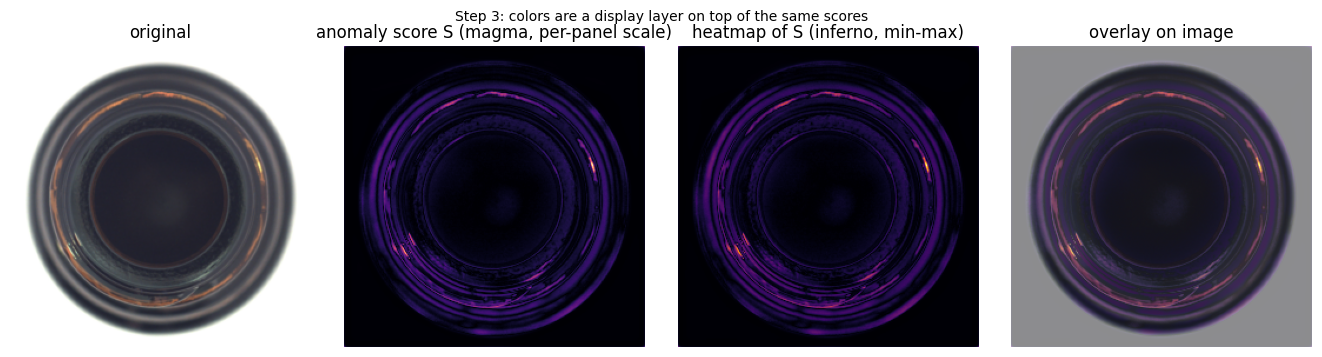

rendering left the raw scores unchanged : True
max score (data) 0.503039  vs  heatmap color: display only
[PASS] src/anomaly/heatmap.py imported and hashed
[PASS] unit verification (normalize/render/overlay/threshold)
[PASS] demo rendered with scores untouched

Step 3 validated. Next: Step 4 - official test-set inference (section below).


In [27]:
# Visual demo: the same scores rendered three ways; the raw scores must not change.
demo_image = smoke_images[0]          # (3, H, W) float, from Step 1
demo_scores = smoke_err_map[0]        # (H, W) raw S, from Step 1
scores_before = demo_scores.clone()

heat_demo = score_to_heatmap(demo_scores, cmap="inferno")
over_demo = overlay_heatmap(demo_image, demo_scores, alpha=0.45)

fig, axes = plt.subplots(1, 4, figsize=(13.5, 3.6))
axes[0].imshow(demo_image.permute(1, 2, 0).clamp(0, 1))
axes[0].set_title("original")
axes[1].imshow(demo_scores, cmap="magma", vmin=0.0, vmax=max(0.05, float(demo_scores.max())))
axes[1].set_title("anomaly score S (magma, per-panel scale)")
axes[2].imshow(heat_demo)
axes[2].set_title("heatmap of S (inferno, min-max)")
axes[3].imshow(over_demo)
axes[3].set_title("overlay on image")
for ax in axes:
    ax.axis("off")
plt.suptitle("Step 3: colors are a display layer on top of the same scores", fontsize=10)
plt.tight_layout()
demo_path = RUN_DIR / "figures" / "step3_display_demo.png"
RUN_DIR.joinpath("figures").mkdir(parents=True, exist_ok=True)
fig.savefig(demo_path, dpi=150, bbox_inches="tight")
plt.show()

scores_unchanged = torch.equal(demo_scores, scores_before)
print(f"rendering left the raw scores unchanged : {scores_unchanged}")
print(f"max score (data) {float(demo_scores.max()):.6f}  vs  heatmap color: display only")
assert scores_unchanged
STEP3_DEMO_OK = True

checks = {
    "src/anomaly/heatmap.py imported and hashed": SRC_HEATMAP_OK,
    "unit verification (normalize/render/overlay/threshold)": STEP3_UNIT_OK,
    "demo rendered with scores untouched": STEP3_DEMO_OK,
}
for name, ok in checks.items():
    print(f"[{'PASS' if ok else 'FAIL'}] {name}")
assert all(checks.values()), "Step 3 checks failed"
print("\nStep 3 validated. Next: Step 4 - official test-set inference (section below).")

## Step 4 - Process the official MVTec AD test split

Rules enforced by the next two cells:

1. **Inference sees images only.** The manifest records each image's path and
   (for later evaluation) the *expected* ground-truth mask path - but masks are
   never opened, resized or passed to the model/scoring here; only their
   existence is verified (every defective test image must have one).
2. **Labels** (`is_defect`) come from the directory structure (`test/good` vs
   `test/<defect>`). They are used for counting and for evaluation *after* the
   scores exist - never inside `reconstruct` / `anomaly_score_map`.
3. **Deterministic order**: normal images first (sorted), then defect types
   alphabetically (sorted) - so saved archives are reproducible.

Counts are taken from the on-disk scan report (20 normal + 63 defective with
63 masks for the real `bottle` category) and cross-checked, not hard-coded.

In [28]:
# Build the test manifest: images for inference, mask paths reserved for Step 6.
test_manifest = []
for path in report.test_good:
    test_manifest.append(
        {"path": path, "name": path.name, "defect": "good", "is_defect": False, "mask_path": None}
    )
for defect in sorted(report.test_by_defect):
    for path in report.test_by_defect[defect]:
        mask_path = DATASET_ROOT / CATEGORY / "ground_truth" / defect / f"{path.stem}_mask.png"
        test_manifest.append(
            {"path": path, "name": path.name, "defect": defect, "is_defect": True, "mask_path": mask_path}
        )

n_normal = sum(1 for entry in test_manifest if not entry["is_defect"])
n_defective = len(test_manifest) - n_normal
missing_masks = [
    entry["name"] for entry in test_manifest if entry["is_defect"] and not entry["mask_path"].is_file()
]

assert not missing_masks, f"missing ground-truth masks for {missing_masks}"
assert n_defective == report.n_test_defective, "defective count disagrees with the category scan"
assert n_normal == len(report.test_good), "normal count disagrees with the category scan"
assert report.ok, "\n".join(report.errors)

type_counts = {}
for entry in test_manifest:
    type_counts[entry["defect"]] = type_counts.get(entry["defect"], 0) + 1
print(f"{'split':<24} {'count':>6}")
for name, count in sorted(type_counts.items()):
    label = "test/good (normal)" if name == "good" else f"test/{name} (defective)"
    print(f"{label:<24} {count:>6}")
print(f"{'total test images':<24} {len(test_manifest):>6}")
print(f"{'mask paths verified':<24} {n_defective:>6}  (existence only - masks not loaded yet)")
STEP4_MANIFEST_OK = True

split                     count
test/broken_large (defective)     20
test/broken_small (defective)     22
test/contamination (defective)     21
test/good (normal)           20
total test images            83
mask paths verified          63  (existence only - masks not loaded yet)


In [29]:
# Inference over the whole test split: images only -> reconstructions -> score maps.
import time

from torch.utils.data import DataLoader

test_dataset = NormalImageDataset([entry["path"] for entry in test_manifest], transform)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False, num_workers=0)

score_chunks, image_score_chunks = [], []
started = time.perf_counter()
for batch in test_loader:
    images = batch["image"].to(DEVICE)
    recon = reconstruct(model, images)          # eval-mode forward, no autograd
    scores = anomaly_score_map(recon, images)   # (B, H, W) - no labels, no masks
    score_chunks.append(scores.cpu())
    image_score_chunks.append(image_score(scores, "mean").cpu())
elapsed = time.perf_counter() - started

score_maps = torch.cat(score_chunks)            # (N, H, W)
image_scores = torch.cat(image_score_chunks)    # (N,)
labels_np = np.array([entry["is_defect"] for entry in test_manifest], dtype=np.int64)

assert score_maps.shape == (len(test_manifest), cfg.data.image_size, cfg.data.image_size), (
    f"expected ({len(test_manifest)}, {cfg.data.image_size}, {cfg.data.image_size}), "
    f"got {tuple(score_maps.shape)}"
)
assert image_scores.shape == (len(test_manifest),) and labels_np.shape == (len(test_manifest),)
assert bool(torch.isfinite(score_maps).all()) and bool((score_maps >= 0).all())
assert int(labels_np.sum()) == n_defective and int((labels_np == 0).sum()) == n_normal

score_maps_np = score_maps.numpy()
print(f"images processed    : {len(test_manifest)} in {elapsed:.1f}s on {DEVICE}")
print(f"score maps          : {tuple(score_maps.shape)}  {score_maps_np.nbytes / 1e6:.1f} MB")
print(f"image score (mean)  : normal {float(image_scores[labels_np == 0].mean()):.6f} | "
      f"defective {float(image_scores[labels_np == 1].mean()):.6f}  (descriptive, not a metric)")
print("per defect type (descriptive preview of image scores):")
for defect in sorted(type_counts):
    if defect == "good":
        continue
    idx = [i for i, entry in enumerate(test_manifest) if entry["defect"] == defect]
    print(f"  {defect:<20} n={len(idx):<3} mean image score {float(image_scores[idx].mean()):.6f}")
print("\nAUROC/AP come in Step 6; thresholds come in Step 5 - still zero masks loaded.")
STEP4_INFERENCE_OK = True

images processed    : 83 in 3.0s on cuda
score maps          : (83, 256, 256)  21.8 MB
image score (mean)  : normal 0.027671 | defective 0.030640  (descriptive, not a metric)
per defect type (descriptive preview of image scores):
  broken_large         n=20  mean image score 0.030639
  broken_small         n=22  mean image score 0.029254
  contamination        n=21  mean image score 0.032093

AUROC/AP come in Step 6; thresholds come in Step 5 - still zero masks loaded.


## Step 5 - Choose a threshold without test leakage

**Pre-registered strategy (chosen here, before any mask is loaded):**

- **Pixel threshold `t_px`** = the **99.5th percentile** of anomaly scores `S`
  computed on the **held-out normal validation split** (`val_paths` inside
  `split_info.json` - the normal-only, `train/good`-derived split used during
  training for model selection; never test data, never defective images).
- **Image threshold `t_img`** = the **95th percentile** of the image scores of
  those same normal validation images. Used only for descriptive FP/FN image
  counts; image AUROC does not need any threshold.

**Leakage rule:** a threshold tuned to maximise Dice on the *test* masks would
inflate the very numbers we report. The cell below asserts that every threshold
source path lives under `train/good`, so no defective or test image can
contribute to `t_px`.

**Trade-offs between false positives and false negatives:**

| | threshold too low | threshold too high |
|---|---|---|
| predicted region | large | small |
| false positives (background flagged) | many | few |
| false negatives (defect missed) | few | many |
| Dice/IoU | dragged down by FP | dragged down by FN |
| AUROC / average precision | unchanged - threshold-free | unchanged |

The 99.5th percentile allows ~0.5% of *normal* validation pixels to exceed
`t_px` - a documented compromise, not a fitted optimum. Sensitivity to this
percentile is a later ablation question; every Dice/IoU number in Step 6 is
computed at this fixed value and reported together with it.

In [30]:
# Threshold from NORMAL validation scores only (asserted), then an FP preview.
split_info = json.loads((RUN_DIR / "split_info.json").read_text(encoding="utf-8"))
val_paths = [Path(p) for p in split_info.get("val_paths", [])]
assert val_paths, "split_info.json contains no val_paths - cannot derive a threshold"
all_normal = all(p.parent.name == "good" and p.parent.parent.name == "train" for p in val_paths)
assert all_normal, "threshold source must live under train/good - leakage detected"
test_path_set = {str(entry["path"]) for entry in test_manifest}
assert not any(str(p) in test_path_set for p in val_paths), "validation paths overlap test paths"

val_dataset = NormalImageDataset(val_paths, transform)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=0)
val_chunks = []
for batch in val_loader:
    images = batch["image"].to(DEVICE)
    val_chunks.append(anomaly_score_map(reconstruct(model, images), images).cpu())
val_score_maps = torch.cat(val_chunks)
val_pixel_scores = val_score_maps.flatten().numpy()
val_image_scores = val_score_maps.mean(dim=(1, 2)).numpy()

PIXEL_PERCENTILE = 99.5
IMAGE_PERCENTILE = 95.0
pixel_threshold = select_percentile_threshold(val_pixel_scores, PIXEL_PERCENTILE)
image_threshold = select_percentile_threshold(val_image_scores, IMAGE_PERCENTILE)

print(f"source: {len(val_paths)} held-out normal train/good images -> {val_pixel_scores.size} pixel scores")
print("normal-validation pixel-score distribution:")
for q in (50.0, 90.0, 99.0, 99.5, 99.9, 100.0):
    print(f"  P{q:<6} {np.percentile(val_pixel_scores, q):.6f}")
print(f"PIXEL threshold (P{PIXEL_PERCENTILE} of normal val pixels) = {pixel_threshold:.6f}")
print(f"IMAGE threshold (P{IMAGE_PERCENTILE} of {len(val_paths)} normal val image scores) = {image_threshold:.6f}")

# contract checks of the selector itself
selector_ok = True
known = np.arange(1000.0)
selector_ok &= abs(select_percentile_threshold(known, 50.0) - float(np.percentile(known, 50.0))) < 1e-9
selector_ok &= abs(select_percentile_threshold(known, 99.9) - float(np.percentile(known, 99.9))) < 1e-9
selector_ok &= _raises(lambda: select_percentile_threshold(known, 100.0), ValueError)
selector_ok &= _raises(lambda: select_percentile_threshold(known, 0.0), ValueError)
selector_ok &= _raises(lambda: select_percentile_threshold(np.array([-1.0]), 50.0), ValueError)
selector_ok &= _raises(lambda: select_percentile_threshold(np.array([]), 50.0), ValueError)
print(f"select_percentile_threshold contract : {'PASS' if selector_ok else 'FAIL'}")
assert selector_ok

# FP preview on NORMAL test images only - still no mask involved
normal_pred = apply_threshold(score_maps_np[labels_np == 0], pixel_threshold)
fp_pixels_per_normal = normal_pred.sum(axis=(1, 2))
images_flagged = int((fp_pixels_per_normal > 0).sum())
print(
    f"normal TEST images with any predicted defect: {images_flagged}/{int((labels_np == 0).sum())} "
    f"(mean predicted pixels {float(fp_pixels_per_normal.mean()):.1f})"
)
THRESHOLD_SOURCE_OK = all_normal
STEP5_OK = True

source: 21 held-out normal train/good images -> 1376256 pixel scores
normal-validation pixel-score distribution:
  P50.0   0.015211
  P90.0   0.068445
  P99.0   0.128357
  P99.5   0.151325
  P99.9   0.262337
  P100.0  0.631071
PIXEL threshold (P99.5 of normal val pixels) = 0.151325
IMAGE threshold (P95.0 of 21 normal val image scores) = 0.028108
select_percentile_threshold contract : PASS
normal TEST images with any predicted defect: 20/20 (mean predicted pixels 605.2)


## Step 6 - Evaluation metrics (`src/evaluation/metrics.py`)

Protocols used here (stated whenever a number is shown):

| Metric | Protocol | Needs both classes? |
|---|---|---|
| **Image AUROC** | image scores vs. image labels, threshold-free | **yes** - raises if only one class |
| **Pixel AUROC** | ALL test pixels pooled into one ranking problem | **yes** (needs a defect and a non-defect pixel) |
| **Pixel AP** | same pooling, step-wise precision integration with ties grouped - identical semantics to `sklearn.average_precision_score`; sensitive to defect rarity | needs >= 1 defect pixel |
| **Dice / IoU** | overlap of the **thresholded** prediction with ground truth, per image | always defined; empty-mask convention below |

**Dice and IoU are meaningless without a thresholding method** - every value
printed below is computed at the Step-5 threshold (99.5th percentile of
*normal validation* pixel scores) and printed next to it.

**Empty-mask convention** (all normal images have empty ground truth): both
prediction and ground truth empty -> `1.0` (agreement on "no defect"), any
other empty side -> `0.0`. Headline Dice/IoU = mean over **defective images
only** (averaging in easy normal/normal agreements would inflate the score);
the arrays keep every case visible.

**Validation** below: hand-worked examples (AUROC 0.75 case, tied scores ->
0.5, AP 5/6 case, Dice 0.5 / IoU 1/3, empty conventions) plus a cross-check
against scikit-learn on random data with many ties when it is installed.

In [31]:
# Step 6 verification: hand-worked examples + sklearn cross-check when available.
from src.evaluation import (
    binary_auroc,
    dice_score,
    image_auroc,
    iou_score,
    pixel_average_precision,
    pixel_auroc,
)

results = []

# hand-worked AUROC
results.append(("AUROC perfect separation = 1.0", binary_auroc([0.1, 0.2, 0.8, 0.9], [0, 0, 1, 1]) == 1.0))
results.append(("AUROC known case = 0.75", abs(binary_auroc([0.3, 0.9, 0.2, 0.8], [1, 1, 0, 0]) - 0.75) < 1e-12))
results.append(("AUROC all tied = 0.5", abs(binary_auroc([0.5, 0.5, 0.5, 0.5], [0, 1, 0, 1]) - 0.5) < 1e-12))
results.append(("AUROC inverted = 0.0", binary_auroc([0.1, 0.2, 0.8, 0.9], [1, 1, 0, 0]) == 0.0))
results.append(("single class raises (both needed)", _raises(lambda: image_auroc([0.1, 0.2], [1, 1]), ValueError)))

# hand-worked average precision
ap_known = pixel_average_precision(np.array([[0.9, 0.8], [0.7, 0.6]]), np.array([[1, 0], [1, 0]]))
results.append((f"AP known case = (1+2/3)/2 (got {ap_known:.6f})", abs(ap_known - (1 + 2 / 3) / 2) < 1e-12))
ap_tie = pixel_average_precision(np.array([[0.8, 0.8]]), np.array([[1, 0]]))
results.append((f"AP tied scores = 0.5 (got {ap_tie:.6f})", abs(ap_tie - 0.5) < 1e-12))
results.append(("AP without defect pixel raises", _raises(lambda: pixel_average_precision(np.zeros((2, 2)), np.zeros((2, 2))), ValueError)))

# hand-worked overlap + empty conventions
known_pred = np.array([[1, 1], [0, 0]])
known_gt = np.array([[1, 0], [1, 0]])
results.append((f"Dice known case = 0.5 (got {dice_score(known_pred, known_gt):.6f})", abs(dice_score(known_pred, known_gt) - 0.5) < 1e-12))
results.append((f"IoU known case = 1/3 (got {iou_score(known_pred, known_gt):.6f})", abs(iou_score(known_pred, known_gt) - 1 / 3) < 1e-12))
empty = np.zeros((4, 4), dtype=bool)
results.append(("both empty -> 1.0 (dice and iou)", dice_score(empty, empty) == 1.0 and iou_score(empty, empty) == 1.0))
results.append(("empty pred vs full gt -> 0", dice_score(empty, ~empty) == 0.0 and iou_score(~empty, empty) == 0.0))
results.append(("float scores as masks raise", _raises(lambda: dice_score(np.full((2, 2), 0.7), np.ones((2, 2))), ValueError)))

# cross-check against scikit-learn (random data, deliberately many ties)
try:
    from sklearn.metrics import average_precision_score, roc_auc_score

    rng = np.random.default_rng(0)
    s_rand = rng.integers(0, 5, size=400).astype(float)
    y_rand = rng.integers(0, 2, size=400)
    maps_rand = rng.normal(size=(6, 16, 16))
    masks_rand = np.zeros((6, 16, 16), dtype=bool)
    masks_rand[rng.random((6, 16, 16)) < 0.03] = True
    results.append((
        "AUROC matches sklearn",
        abs(binary_auroc(s_rand, y_rand) - roc_auc_score(y_rand, s_rand)) < 1e-9,
    ))
    results.append((
        "pixel AUROC matches sklearn",
        abs(pixel_auroc(maps_rand, masks_rand) - roc_auc_score(masks_rand.ravel().astype(int), maps_rand.ravel())) < 1e-9,
    ))
    results.append((
        "pixel AP matches sklearn",
        abs(pixel_average_precision(maps_rand, masks_rand) - average_precision_score(masks_rand.ravel().astype(int), maps_rand.ravel())) < 1e-9,
    ))
    print("sklearn cross-check: performed on random data with ties\n")
except ImportError:
    print("sklearn not installed on this runtime: hand examples are the validation\n")

for name, ok in results:
    print(f"[{'PASS' if ok else 'FAIL'}] {name}")
all_ok = all(ok for _, ok in results)
assert all_ok, "metrics.py verification failed"
print(f"\n{len(results)} checks passed.")
STEP6_UNIT_OK = True

sklearn cross-check: performed on random data with ties

[PASS] AUROC perfect separation = 1.0
[PASS] AUROC known case = 0.75
[PASS] AUROC all tied = 0.5
[PASS] AUROC inverted = 0.0
[PASS] single class raises (both needed)
[PASS] AP known case = (1+2/3)/2 (got 0.833333)
[PASS] AP tied scores = 0.5 (got 0.500000)
[PASS] AP without defect pixel raises
[PASS] Dice known case = 0.5 (got 0.500000)
[PASS] IoU known case = 1/3 (got 0.333333)
[PASS] both empty -> 1.0 (dice and iou)
[PASS] empty pred vs full gt -> 0
[PASS] float scores as masks raise
[PASS] AUROC matches sklearn
[PASS] pixel AUROC matches sklearn
[PASS] pixel AP matches sklearn

16 checks passed.


In [32]:
# Masks now: threshold predictions, load ground truth (scores already exist), compute metrics.
from PIL import Image as PILImage

_RESAMPLE_NEAREST = getattr(PILImage, "Resampling", PILImage).NEAREST

pred_masks = apply_threshold(score_maps_np, pixel_threshold)          # (N, H, W) bool
gt_masks = np.zeros_like(pred_masks)
for index, entry in enumerate(test_manifest):
    if entry["is_defect"]:
        with PILImage.open(entry["mask_path"]) as mask_img:
            mask_array = np.asarray(
                mask_img.convert("L").resize(
                    (cfg.data.image_size, cfg.data.image_size), _RESAMPLE_NEAREST
                )
            )
        gt_masks[index] = mask_array > 127

assert int(gt_masks.sum()) > 0, "no positive ground-truth pixels found"
assert int(gt_masks[labels_np == 0].sum()) == 0, "normal images must have empty ground truth"

image_auroc_value = image_auroc(image_scores.numpy(), labels_np)
pixel_auroc_value = pixel_auroc(score_maps_np, gt_masks)
pixel_ap_value = pixel_average_precision(score_maps_np, gt_masks)
dice_all = dice_score(pred_masks, gt_masks)
iou_all = iou_score(pred_masks, gt_masks)

defective = labels_np == 1
normal = labels_np == 0
dice_defective_mean = float(dice_all[defective].mean())
iou_defective_mean = float(iou_all[defective].mean())
normal_pred_area = pred_masks[normal].sum(axis=(1, 2))
fp_normal_images = int((normal_pred_area > 0).sum())
fp_normal_pixels = int(normal_pred_area.sum())
missed = np.where(defective & (iou_all == 0.0))[0]
missed_names = [test_manifest[i]["name"] for i in missed]

per_type = {}
for defect in sorted({e["defect"] for e in test_manifest if e["is_defect"]}):
    idx = np.array([i for i, e in enumerate(test_manifest) if e["defect"] == defect])
    per_type[defect] = {
        "n": int(idx.size),
        "dice_mean": float(dice_all[idx].mean()),
        "iou_mean": float(iou_all[idx].mean()),
    }

threshold_note = (
    f"threshold = P{PIXEL_PERCENTILE} of normal-validation pixel scores = {pixel_threshold:.6f}"
)
print(f"THRESHOLD       {threshold_note}")
print(f"{'metric':<26} {'value':>10}")
print(f"{'image AUROC':<26} {image_auroc_value:>10.4f}")
print(f"{'pixel AUROC (pooled)':<26} {pixel_auroc_value:>10.4f}")
print(f"{'pixel AP (pooled)':<26} {pixel_ap_value:>10.4f}")
print(f"{'Dice (defective mean)':<26} {dice_defective_mean:>10.4f}   [{threshold_note}]")
print(f"{'IoU (defective mean)':<26} {iou_defective_mean:>10.4f}   [{threshold_note}]")
print(f"{'Dice (all images mean)':<26} {float(dice_all.mean()):>10.4f}   [incl. empty-mask convention 1.0]")
print(f"{'IoU (all images mean)':<26} {float(iou_all.mean()):>10.4f}   [incl. empty-mask convention 1.0]")
print("\nper defect type:")
for defect, values in per_type.items():
    print(f"  {defect:<20} n={values['n']:<3} dice {values['dice_mean']:.4f}  iou {values['iou_mean']:.4f}")
print(f"\nnormal images flagged as defective : {fp_normal_images}/{int(normal.sum())} "
      f"({fp_normal_pixels} predicted pixels total)")
print(f"defective images with IoU = 0      : {len(missed)} {missed_names}")

for value in (image_auroc_value, pixel_auroc_value, pixel_ap_value,
              dice_defective_mean, iou_defective_mean, float(dice_all.mean()), float(iou_all.mean())):
    assert 0.0 <= value <= 1.0, f"metric out of range: {value}"
assert n_normal > 0 and n_defective > 0, "image AUROC needs both classes present"
assert gt_masks[defective].sum() > 0 and (~gt_masks).sum() > 0, "pixel metrics need both classes"
STEP6_METRICS_OK = True
print("\nAll metric values above come from this run's scores + masks (nothing hand-filled).")

THRESHOLD       threshold = P99.5 of normal-validation pixel scores = 0.151325
metric                          value
image AUROC                    0.8016
pixel AUROC (pooled)           0.7563
pixel AP (pooled)              0.1865
Dice (defective mean)          0.1753   [threshold = P99.5 of normal-validation pixel scores = 0.151325]
IoU (defective mean)           0.1027   [threshold = P99.5 of normal-validation pixel scores = 0.151325]
Dice (all images mean)         0.1331   [incl. empty-mask convention 1.0]
IoU (all images mean)          0.0780   [incl. empty-mask convention 1.0]

per defect type:
  broken_large         n=20  dice 0.1471  iou 0.0815
  broken_small         n=22  dice 0.2786  iou 0.1670
  contamination        n=21  dice 0.0940  iou 0.0555

normal images flagged as defective : 20/20 (12105 predicted pixels total)
defective images with IoU = 0      : 5 ['002.png', '011.png', '012.png', '016.png', '020.png']

All metric values above come from this run's scores + masks (no

## Step 7 - Visualize detections and failure cases

One figure per example category, each row = one image, six labeled panels:

1. original, 2. reconstruction, 3. absolute error `|I - Î|` (channel mean),
4. anomaly heatmap, 5. ground-truth mask, 6. predicted binary mask.

For this baseline panels 3 and 4 hold **the same numbers** `S` - panel 3 is
rendered with `magma`, panel 4 with `inferno`; both are pinned to one global
range (`vmax` = max score over all selected images) so colors are comparable
across every row and figure. The predicted mask uses the Step-5 threshold and
is labeled with it.

Categories are **computed**, not hand-picked: successful = highest Dice with
non-empty intersection; missed = zero intersection (IoU 0), padded with the
weakest detections if fewer than three exist; false positives = normal images
with any predicted pixels (top by area); normal examples = highest-scoring
normal images. Counts of each category are printed honestly - a category with
no members is reported, not faked.

category counts: normal examples 3, successful 3, false positives 3, missed/weakest 3 (of 63 defective, 20 normal)


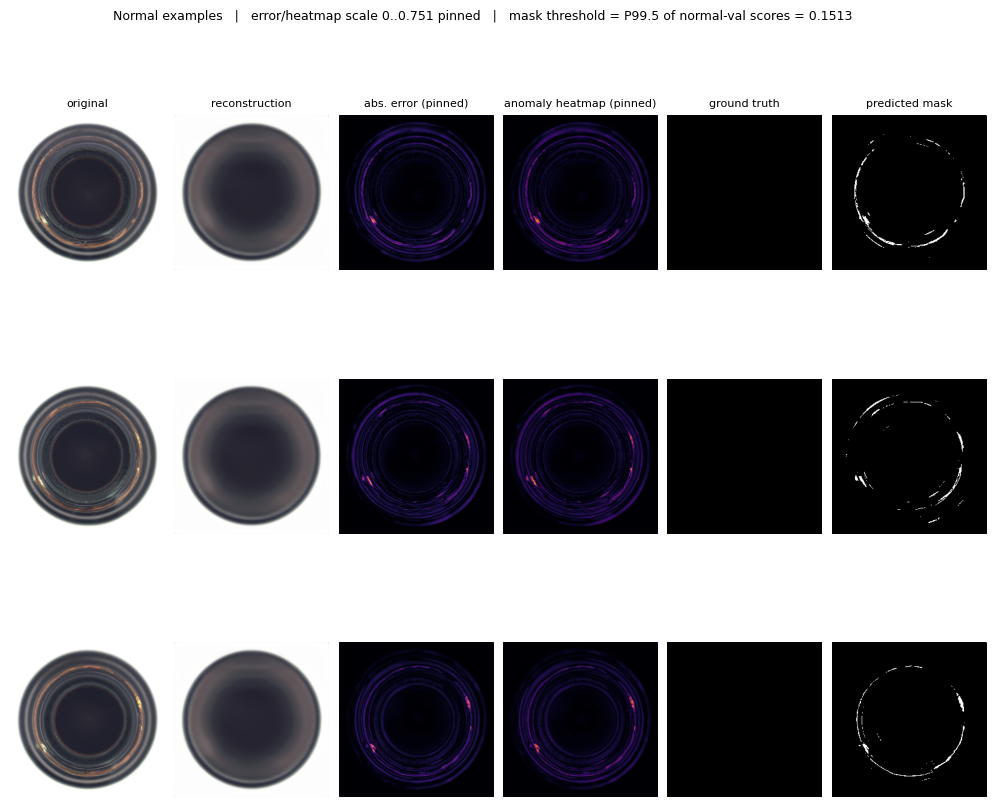

saved: /content/edge-aware-anomaly-detection/outputs/runs/baseline_bottle/figures/step7_normal_examples.png


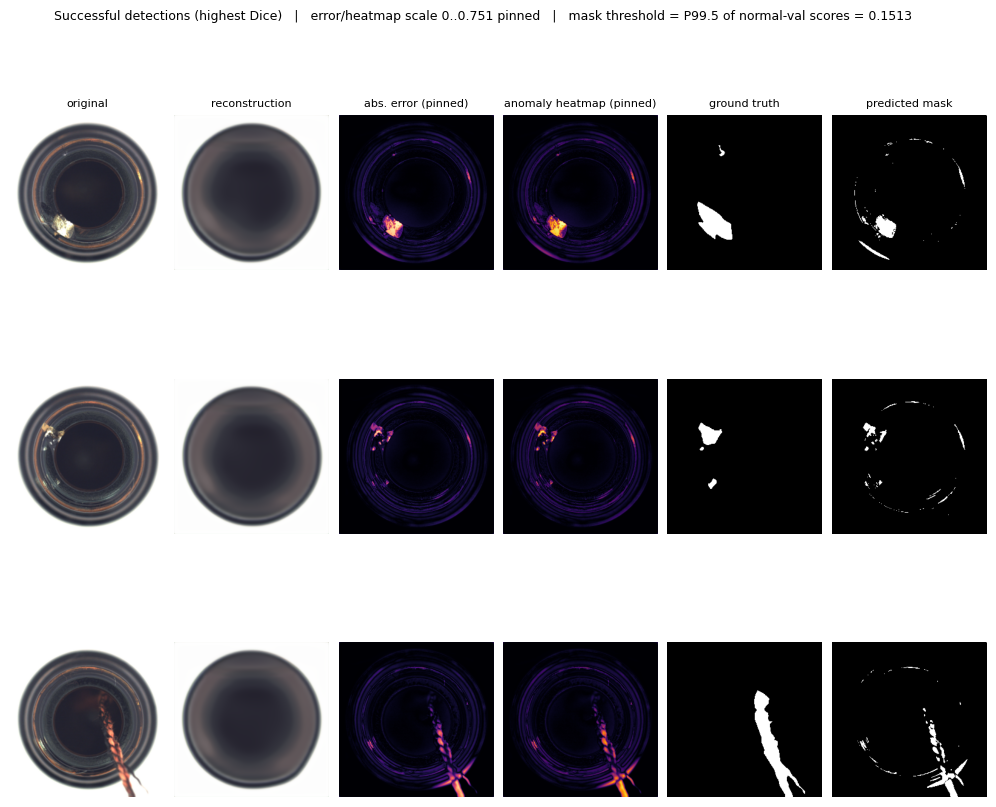

saved: /content/edge-aware-anomaly-detection/outputs/runs/baseline_bottle/figures/step7_successful_detections.png


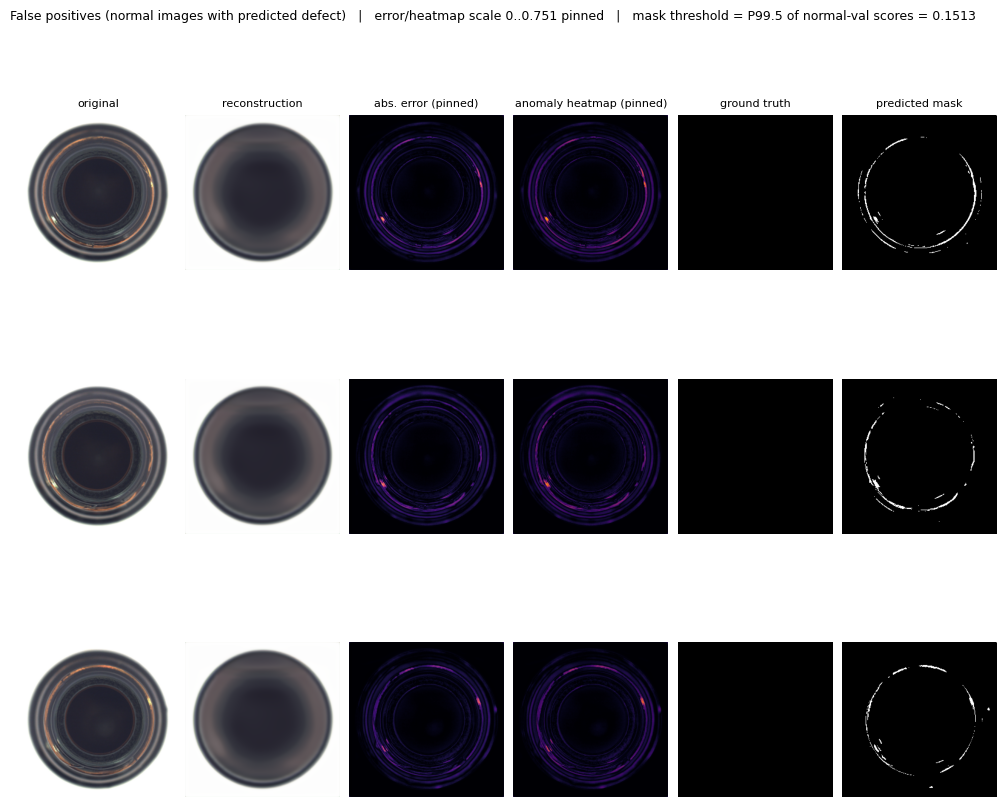

saved: /content/edge-aware-anomaly-detection/outputs/runs/baseline_bottle/figures/step7_false_positives.png


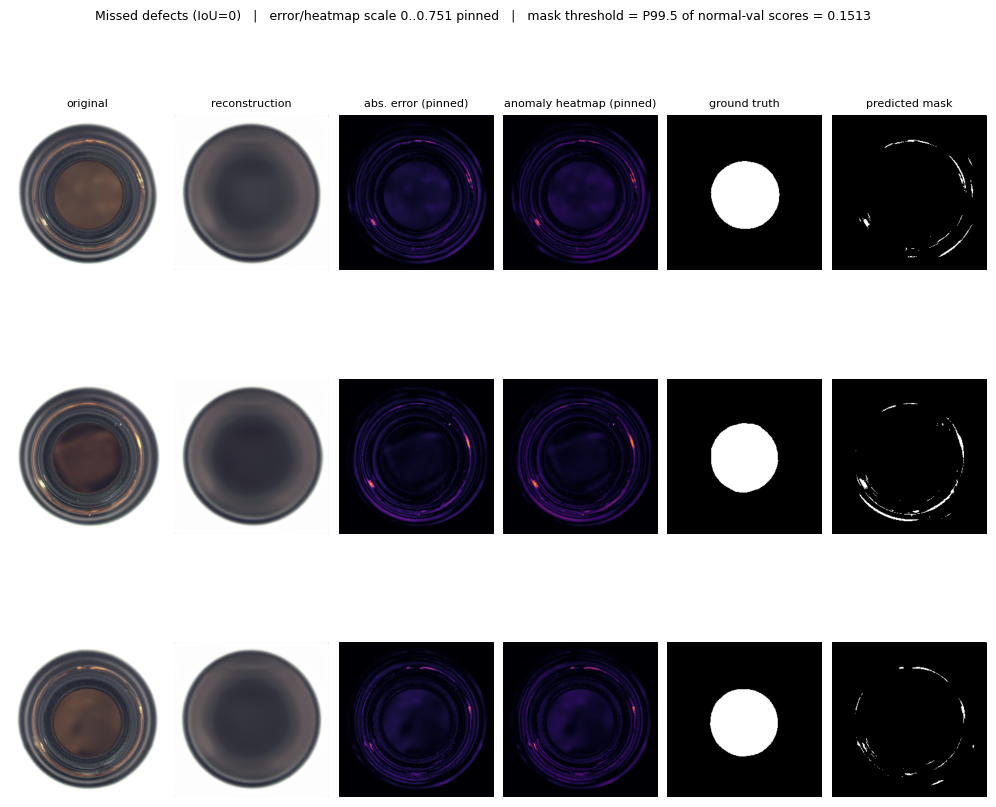

saved: /content/edge-aware-anomaly-detection/outputs/runs/baseline_bottle/figures/step7_missed_defects.png

Step 7: 4 category figures saved under /content/edge-aware-anomaly-detection/outputs/runs/baseline_bottle/figures


In [33]:
# Step 7: categorize examples, recompute their reconstructions, render the grids.
inter = (pred_masks & gt_masks).sum(axis=(1, 2)).astype(int)
gt_area = gt_masks.sum(axis=(1, 2)).astype(int)
pred_area = pred_masks.sum(axis=(1, 2)).astype(int)
defective_idx = np.where(labels_np == 1)[0]
normal_idx = np.where(labels_np == 0)[0]

by_dice = sorted(defective_idx, key=lambda i: float(dice_all[i]), reverse=True)
successful = [i for i in by_dice if inter[i] > 0][:3]
missed = sorted(
    [i for i in defective_idx if inter[i] == 0], key=lambda i: gt_area[i], reverse=True
)[:3]
if len(missed) < 3:
    weakest = [i for i in reversed(by_dice) if inter[i] > 0 and i not in missed]
    missed = missed + weakest[: 3 - len(missed)]
    missed_label = "Missed defects (IoU=0) + weakest detections"
else:
    missed_label = "Missed defects (IoU=0)"
normal_fp = [i for i in sorted(normal_idx, key=lambda i: int(pred_area[i]), reverse=True) if pred_area[i] > 0][:3]
normal_examples = sorted(normal_idx, key=lambda i: float(image_scores[i]), reverse=True)[:3]

print(f"category counts: normal examples {len(normal_examples)}, successful {len(successful)}, "
      f"false positives {len(normal_fp)}, missed/weakest {len(missed)} (of {n_defective} defective, {n_normal} normal)")
if not normal_fp:
    print("note: no normal image has any predicted defect pixel at this threshold - "
          "false-positive category is empty (honest: nothing to show).")

selected = sorted(set(successful + missed + normal_fp + normal_examples))
sel_paths = [test_manifest[i]["path"] for i in selected]
sel_dataset = NormalImageDataset(sel_paths, transform)
sel_images = torch.stack([sel_dataset[k]["image"] for k in range(len(sel_dataset))]).to(DEVICE)
sel_recon = reconstruct(model, sel_images)
sel_scores = anomaly_score_map(sel_recon, sel_images)     # channel-mean |I - x_hat|
row_of = {manifest_index: k for k, manifest_index in enumerate(selected)}

err_vmax = max(0.05, float(sel_scores.max()))             # one pinned scale for the whole step
heat_vmax = err_vmax


def render_category(label, indices, filename):
    if not indices:
        print(f"[skip] {label}: empty category")
        return False
    fig = plt.figure(figsize=(12.6, 2.7 * len(indices) + 1.1))
    gs = fig.add_gridspec(len(indices), 6, hspace=0.45, wspace=0.06)
    panel_titles = ["original", "reconstruction", "abs. error (pinned)", "anomaly heatmap (pinned)", "ground truth", "predicted mask"]
    for row, manifest_index in enumerate(indices):
        k = row_of[manifest_index]
        entry = test_manifest[manifest_index]
        image_t = sel_images[k].cpu()
        recon_t = sel_recon[k].cpu()
        scores_t = sel_scores[k].cpu()
        if entry["is_defect"]:
            row_label = f"{entry['name']}\ndice {dice_all[manifest_index]:.3f} iou {iou_all[manifest_index]:.3f}"
        else:
            row_label = f"{entry['name']}\npred px {int(pred_area[manifest_index])}"

        panels = [
            image_t.permute(1, 2, 0).clamp(0, 1),
            recon_t.permute(1, 2, 0).clamp(0, 1),
            scores_t,
            score_to_heatmap(scores_t, vmin=0.0, vmax=heat_vmax),
            gt_masks[manifest_index],
            pred_masks[manifest_index],
        ]
        for col, panel in enumerate(panels):
            ax = fig.add_subplot(gs[row, col])
            if col in (2,):
                ax.imshow(panel, cmap="magma", vmin=0.0, vmax=err_vmax)
            elif col in (4, 5):
                ax.imshow(panel, cmap="gray", vmin=0.0, vmax=1.0)
            else:
                ax.imshow(panel)
            if row == 0:
                ax.set_title(panel_titles[col], fontsize=8)
            if col == 0:
                ax.set_ylabel(row_label, fontsize=6, rotation=0)
            ax.axis("off")
    plt.suptitle(
        f"{label}   |   error/heatmap scale 0..{err_vmax:.3f} pinned   |   "
        f"mask threshold = P{PIXEL_PERCENTILE} of normal-val scores = {pixel_threshold:.4f}",
        fontsize=9,
    )
    out = RUN_DIR / "figures" / filename
    fig.savefig(out, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"saved: {out}")
    return True


rendered = 0
rendered += render_category("Normal examples", normal_examples, "step7_normal_examples.png")
rendered += render_category("Successful detections (highest Dice)", successful, "step7_successful_detections.png")
rendered += render_category("False positives (normal images with predicted defect)", normal_fp, "step7_false_positives.png")
rendered += render_category(missed_label, missed, "step7_missed_defects.png")

assert rendered >= 1, "no figures rendered"
STEP7_OK = True
print(f"\nStep 7: {rendered} category figures saved under {RUN_DIR / 'figures'}")

## Step 8 - Save results reproducibly

Everything lands under `outputs/runs/baseline_bottle/evaluation/` (and
`figures/`) - inside `outputs/`, which `.gitignore` excludes, so no large
artifact enters git:

- `eval_config.json` - **configuration**: checkpoint id, category, image
  resolution, scoring definition, threshold method + values + source counts,
  display pins, environment (Python/torch/CUDA/GPU/device), notebook name.
- `per_image_results.csv` - per-image scores, predicted labels, TP/FP/FN,
  Dice/IoU (with the threshold recorded in `eval_config.json`).
- `metrics.json` - metric summaries incl. conventions (empty-mask rule,
  pooling, per-type means, missed-defect list, normal FP counts).
- `failure_cases.json` - IoU=0 defects and worst normal false positives with
  their figure files.
- `anomaly_maps.npz` - raw score maps, ground-truth masks, image scores,
  labels and paths, so metrics can be recomputed without re-running inference.
- `figures/*.png` - every visualization from Steps 1, 3 and 7.

The cell ends with a **checklist of all eight steps** and an audit that the
artifacts exist and `.gitignore` still covers `outputs/`.

In [34]:
# Step 8: persist configuration, scores, metrics, threshold details, failures.
import platform

import pandas as pd

EVAL_DIR = RUN_DIR / "evaluation"
EVAL_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR = RUN_DIR / "figures"

eval_config = {
    "notebook": "04_anomaly_detection.ipynb",
    "created": time.strftime("%Y-%m-%dT%H:%M:%S%z"),
    "checkpoint": {
        "id_sha256_12": CHECKPOINT_ID,
        "path": str(BEST_CKPT),
        "epoch": int(payload["epoch"]),
        "best_val_metric": payload.get("best_metric"),
    },
    "experiment": cfg.experiment_name,
    "category": CATEGORY,
    "seed": SEED,
    "image_size": cfg.data.image_size,
    "normalization": "ToTensor -> float32 [0, 1] CHW; sigmoid decoder output",
    "scoring": "baseline S(x,y) = mean_c |I - x_hat| (src.anomaly.scoring.anomaly_score_map)",
    "inference": {"batch_size": 16, "device": str(DEVICE), "model_mode": "eval()"},
    "threshold": {
        "pixel": {
            "method": "percentile of anomaly scores on NORMAL validation images",
            "source": "held-out normal train/good split (split_info.json val_paths)",
            "percentile": PIXEL_PERCENTILE,
            "value": pixel_threshold,
            "n_source_images": len(val_paths),
            "n_source_pixels": int(val_pixel_scores.size),
            "test_leakage": "none - no test image, defective image or mask contributed",
        },
        "image": {
            "method": "percentile of image scores on the same normal validation images",
            "percentile": IMAGE_PERCENTILE,
            "value": image_threshold,
            "n_source_images": len(val_paths),
        },
    },
    "display": {
        "heatmap_cmap": "inferno",
        "error_cmap": "magma",
        "grid_vmin": 0.0,
        "grid_vmax": err_vmax,
        "note": "display pins only; metrics always consume raw S",
    },
    "counts": {
        "test_normal": n_normal,
        "test_defective": n_defective,
        "defect_types": {k: v for k, v in type_counts.items() if k != "good"},
        "gt_mask_pixels": int(gt_masks.sum()),
    },
    "environment": {
        "python": platform.python_version(),
        "torch": torch.__version__,
        "cuda": torch.version.cuda,
        "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
        "device": str(DEVICE),
    },
}
(EVAL_DIR / "eval_config.json").write_text(json.dumps(eval_config, indent=2), encoding="utf-8")

rows = []
for index, entry in enumerate(test_manifest):
    rows.append(
        {
            "path": str(entry["path"]),
            "name": entry["name"],
            "defect_type": entry["defect"],
            "is_defect": int(entry["is_defect"]),
            "image_score_mean": float(image_scores[index]),
            "image_score_max": float(score_maps_np[index].max()),
            "predicted_label_at_image_threshold": int(float(image_scores[index]) > image_threshold),
            "gt_pixels": int(gt_masks[index].sum()),
            "pred_pixels": int(pred_masks[index].sum()),
            "tp": int((pred_masks[index] & gt_masks[index]).sum()),
            "fp": int((pred_masks[index] & ~gt_masks[index]).sum()),
            "fn": int((~pred_masks[index] & gt_masks[index]).sum()),
            "dice": float(dice_all[index]),
            "iou": float(iou_all[index]),
        }
    )
per_image_df = pd.DataFrame(rows)
per_image_df.to_csv(EVAL_DIR / "per_image_results.csv", index=False)

metrics_payload = {
    "checkpoint_id": CHECKPOINT_ID,
    "category": CATEGORY,
    "n_test_images": len(test_manifest),
    "image_auroc": image_auroc_value,
    "pixel_auroc_pooled": pixel_auroc_value,
    "pixel_average_precision_pooled": pixel_ap_value,
    "dice": {
        "defective_mean": dice_defective_mean,
        "all_images_mean": float(dice_all.mean()),
        "normal_images_mean": float(dice_all[~defective].mean()),
        "empty_mask_convention": 1.0,
        "threshold": f"P{PIXEL_PERCENTILE} of normal-validation pixel scores = {pixel_threshold:.6f}",
    },
    "iou": {
        "defective_mean": iou_defective_mean,
        "all_images_mean": float(iou_all.mean()),
        "normal_images_mean": float(iou_all[~defective].mean()),
        "empty_mask_convention": 1.0,
        "threshold": f"P{PIXEL_PERCENTILE} of normal-validation pixel scores = {pixel_threshold:.6f}",
    },
    "per_defect_type": per_type,
    "normal_false_positives": {
        "images_with_any_prediction": fp_normal_images,
        "total_predicted_pixels": fp_normal_pixels,
        "n_normal_images": n_normal,
    },
    "missed_defects_iou_zero": missed_names,
    "notes": [
        "threshold-free metrics (AUROC/AP) do not depend on the threshold above",
        "Dice/IoU are computed at the stated threshold only; no test-mask tuning was performed",
        "pixel metrics pool all pixels of all test images",
    ],
}
(EVAL_DIR / "metrics.json").write_text(json.dumps(metrics_payload, indent=2), encoding="utf-8")

worst_normal = [
    {
        "name": test_manifest[i]["name"],
        "predicted_pixels": int(pred_area[i]),
        "image_score": float(image_scores[i]),
    }
    for i in sorted(normal_idx, key=lambda i: int(pred_area[i]), reverse=True)[:5]
    if pred_area[i] > 0
]
failure_payload = {
    "missed_defects_iou_zero": [
        {
            "name": test_manifest[i]["name"],
            "defect_type": test_manifest[i]["defect"],
            "gt_pixels": int(gt_area[i]),
            "pred_pixels": int(pred_area[i]),
            "dice": float(dice_all[i]),
            "iou": float(iou_all[i]),
        }
        for i in missed if inter[i] == 0
    ],
    "worst_normal_false_positives": worst_normal,
    "figures": {
        "normal_examples": "figures/step7_normal_examples.png",
        "successful_detections": "figures/step7_successful_detections.png",
        "false_positives": "figures/step7_false_positives.png",
        "missed_or_weakest": "figures/step7_missed_defects.png",
    },
}
(EVAL_DIR / "failure_cases.json").write_text(json.dumps(failure_payload, indent=2), encoding="utf-8")

np.savez_compressed(
    EVAL_DIR / "anomaly_maps.npz",
    score_maps=score_maps_np.astype(np.float32),
    gt_masks=gt_masks,
    pred_masks=pred_masks,
    image_scores=image_scores.numpy().astype(np.float32),
    labels=labels_np,
    paths=np.array([str(entry["path"]) for entry in test_manifest]),
)

required_artifacts = [
    EVAL_DIR / "eval_config.json",
    EVAL_DIR / "per_image_results.csv",
    EVAL_DIR / "metrics.json",
    EVAL_DIR / "failure_cases.json",
    EVAL_DIR / "anomaly_maps.npz",
    FIGURES_DIR / "step1_smoke_reconstruction.png",
    FIGURES_DIR / "step3_display_demo.png",
]
missing_artifacts = [str(p) for p in required_artifacts if not p.is_file()]
assert not missing_artifacts, f"missing evaluation artifacts: {missing_artifacts}"

gitignore_text = (REPO_ROOT / ".gitignore").read_text(encoding="utf-8")
artifacts_gitignored = any(
    line.strip() in ("/outputs/", "outputs/") for line in gitignore_text.splitlines()
)
assert artifacts_gitignored, ".gitignore no longer excludes outputs/ - artifacts could leak into git"

print(f"evaluation directory: {EVAL_DIR}")
for path in sorted(EVAL_DIR.iterdir()):
    print(f"  {path.name:<26} {path.stat().st_size / 1024:>10.1f} KB")
print(f"figures: {len(list(FIGURES_DIR.glob('*.png')))} png files")
print(f".gitignore covers outputs/: {artifacts_gitignored}")
STEP8_ARTIFACTS_OK = True

# ---------------------------------------------------------------- final checklist
def _all(*flags) -> bool:
    return all(bool(flag) for flag in flags)


final_checks = {
    "Step 1 - trained checkpoint validated": _all(
        SRC_OK, RUN_ARTIFACTS_OK, CONFIG_OK, PAYLOAD_OK, WEIGHTS_OK, MODEL_EVAL_OK, DATASET_OK, SCAN_OK, SMOKE_OK
    ),
    "Step 2 - anomaly scoring verified": _all(SRC_SCORING_OK, STEP2_UNIT_OK, STEP2_REAL_OK),
    "Step 3 - heatmaps/threshold masks verified": _all(SRC_HEATMAP_OK, STEP3_UNIT_OK, STEP3_DEMO_OK),
    "Step 4 - test-set inference without labels": _all(STEP4_MANIFEST_OK, STEP4_INFERENCE_OK),
    "Step 5 - threshold from normal data only": _all(THRESHOLD_SOURCE_OK, STEP5_OK),
    "Step 6 - metrics validated and computed": _all(STEP6_UNIT_OK, STEP6_METRICS_OK),
    "Step 7 - detections and failure cases visualized": STEP7_OK,
    "Step 8 - results saved reproducibly": STEP8_ARTIFACTS_OK,
}
width = max(len(name) for name in final_checks)
all_ok = True
for name, ok in final_checks.items():
    ok = bool(ok)
    all_ok = all_ok and ok
    print(f"[{'PASS' if ok else 'FAIL'}] {name}")
assert all_ok, "Phase 3 checklist failed - fix the failing step before reporting results."

print(f"\ncheckpoint id : {CHECKPOINT_ID}")
print(f"threshold     : P{PIXEL_PERCENTILE} of normal-val scores = {pixel_threshold:.6f} "
      f"(source: {len(val_paths)} held-out normal images)")
print(f"key metrics   : image AUROC {image_auroc_value:.4f} | pixel AUROC {pixel_auroc_value:.4f} | "
      f"pixel AP {pixel_ap_value:.4f} | Dice {dice_defective_mean:.4f} | IoU {iou_defective_mean:.4f}")
print("\nAll eight steps executed in this run. Report these values WITH the thresholding")
print("method above; they were computed without any test-mask tuning.")
print("Next research phases: multi-scale scoring, edge-aware loss, ablations vs this baseline.")

evaluation directory: /content/edge-aware-anomaly-detection/outputs/runs/baseline_bottle/evaluation
  anomaly_maps.npz              18255.8 KB
  eval_config.json                  1.8 KB
  failure_cases.json                1.4 KB
  metrics.json                      1.5 KB
  per_image_results.csv            16.3 KB
figures: 8 png files
.gitignore covers outputs/: True
[PASS] Step 1 - trained checkpoint validated
[PASS] Step 2 - anomaly scoring verified
[PASS] Step 3 - heatmaps/threshold masks verified
[PASS] Step 4 - test-set inference without labels
[PASS] Step 5 - threshold from normal data only
[PASS] Step 6 - metrics validated and computed
[PASS] Step 7 - detections and failure cases visualized
[PASS] Step 8 - results saved reproducibly

checkpoint id : aa21e2056301
threshold     : P99.5 of normal-val scores = 0.151325 (source: 21 held-out normal images)
key metrics   : image AUROC 0.8016 | pixel AUROC 0.7563 | pixel AP 0.1865 | Dice 0.1753 | IoU 0.1027

All eight steps executed in t